# VOREKO IA — Evaluación comparativa de modelos preentrenados para la clasificación de incidencias en proyectos de construcción

**Maestría en Inteligencia Artificial — Universidad Tecmilenio**
Gestión de Proyectos de Inteligencia Artificial · Módulo 2 · Semana 5 · Actividad 4
**Autor:** José Ignacio Castillo Camacho

In [1]:
%pip install -q "transformers>=4.56,<6" "datasets>=3.0" "huggingface_hub>=0.34" "accelerate>=1.0" "sentencepiece>=0.2" "protobuf>=4.25" "scikit-learn>=1.4"

# Comprobación de versiones instaladas (sin importar los paquetes todavía)
from importlib.metadata import version, PackageNotFoundError

paquetes = ["torch", "transformers", "datasets", "huggingface_hub", "accelerate", "tokenizers",
            "sentencepiece", "protobuf", "scikit-learn", "pandas", "numpy", "matplotlib"]
for p in paquetes:
    try:
        print(f"{p:<16} {version(p)}")
    except PackageNotFoundError:
        print(f"{p:<16} NO INSTALADO")

torch            2.11.0+cu130
transformers     5.18.0
datasets         4.8.5
huggingface_hub  1.33.0
accelerate       1.15.0
tokenizers       0.23.2
sentencepiece    0.2.2
protobuf         6.33.6
scikit-learn     1.6.1
pandas           2.2.3
numpy            2.1.3
matplotlib       3.10.0


## 3. GPU y entorno de ejecución

In [2]:
!nvidia-smi || echo "nvidia-smi no disponible: no hay GPU asignada a esta sesión"

Mon Oct 12 16:27:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import os, sys, json, platform, random, time, gc, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
from importlib.metadata import version

# Carpetas de trabajo (en Colab se crean dentro de /content)
for carpeta in ["src", "data", "results", "results/figuras"]:
    Path(carpeta).mkdir(parents=True, exist_ok=True)
Path("src/__init__.py").touch()

# Semilla global (la inferencia es determinista; se fija por buena práctica)
SEMILLA = 2026
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)

GPU_DISPONIBLE = torch.cuda.is_available()
entorno = {
    "fecha_ejecucion_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    "python": sys.version.split()[0],
    "plataforma": platform.platform(),
    "torch": torch.__version__,
    "cuda_torch": torch.version.cuda,
    "transformers": transformers.__version__,
    "datasets": version("datasets"),
    "huggingface_hub": version("huggingface_hub"),
    "scikit_learn": version("scikit-learn"),
    "cuda_disponible": GPU_DISPONIBLE,
    "gpu": torch.cuda.get_device_name(0) if GPU_DISPONIBLE else None,
    "memoria_gpu_total_mb": round(torch.cuda.get_device_properties(0).total_memory / 1024**2) if GPU_DISPONIBLE else None,
    "cpu_nucleos": os.cpu_count(),
}
print(json.dumps(entorno, indent=2, ensure_ascii=False))

# Comprobación de versión mínima de transformers (si falla: reiniciar sesión tras la celda 2)
mayor, menor = (int(x) for x in transformers.__version__.split(".")[:2])
assert (mayor, menor) >= (4, 56), (
    f"transformers {transformers.__version__} está cargado en memoria. Reinicia la sesión y ejecuta desde la celda 3."
)

if GPU_DISPONIBLE:
    print(f"\n✅ GPU detectada: {entorno['gpu']} — las mediciones de latencia corresponden a GPU.")
else:
    print("\n⚠️ NO HAY GPU. El experimento se ejecutará en CPU. "
          "Los tiempos NO deben presentarse como mediciones en GPU.")

{
  "fecha_ejecucion_utc": "2026-10-12T16:28:08Z",
  "python": "3.13.15",
  "plataforma": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu130",
  "cuda_torch": "13.0",
  "transformers": "5.18.0",
  "datasets": "4.8.5",
  "huggingface_hub": "1.33.0",
  "scikit_learn": "1.6.1",
  "cuda_disponible": true,
  "gpu": "Tesla T4",
  "memoria_gpu_total_mb": 14913,
  "cpu_nucleos": 2
}

✅ GPU detectada: Tesla T4 — las mediciones de latencia corresponden a GPU.


## 4. Autenticación en Hugging Face Hub

In [4]:
from huggingface_hub import HfApi, login

USAR_LOGIN_INTERACTIVO = False   # cambiar a True si no se usa Colab Secrets
HF_TOKEN = None

try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
    print("Token leído desde Colab Secrets (no se muestra).")
except Exception as e:  # no es Colab, el secreto no existe o no tiene permiso
    print(f"Colab Secrets no disponible ({type(e).__name__}).")

if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)
elif USAR_LOGIN_INTERACTIVO:
    login()
else:
    print("Se continúa sin autenticación: los tres modelos son públicos.")

Colab Secrets no disponible (SecretNotFoundError).
Se continúa sin autenticación: los tres modelos son públicos.


In [5]:
%%writefile src/config.py
# -*- coding: utf-8 -*-
"""
config.py
=========
Configuración única del experimento VOREKO IA. Todos los módulos, pruebas y el
notebook toman de aquí los modelos, etiquetas, plantillas y umbrales para
garantizar condiciones idénticas de evaluación.
"""

from __future__ import annotations

SEMILLA = 2026

# ---------------------------------------------------------------------------
# Modelos evaluados (verificados en Hugging Face el 2026-10-09)
# ---------------------------------------------------------------------------
# Los valores de parámetros y tamaño provienen de la API pública del Hub
# (campo safetensors.total y tamaño de model.safetensors). Son datos
# publicados, NO mediciones propias.
MODELOS = {
    "MiniLMv2-L6": {
        "id": "MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli",
        "arquitectura": "Multilingual MiniLMv2 (6 capas, destilado de XLM-RoBERTa-large)",
        "parametros_publicados": 106_995_589,
        "tamano_safetensors_mb": 428.0,
        "licencia": "MIT",
        "xnli_es_publicado": 0.748,   # ficha del modelo (XNLI test, español)
    },
    "mDeBERTa-v3-base": {
        "id": "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
        "arquitectura": "mDeBERTa-v3-base (12 capas)",
        "parametros_publicados": 278_812_163,
        "tamano_safetensors_mb": 557.7,
        "licencia": "MIT",
        "xnli_es_publicado": 0.845,
    },
    "XLM-RoBERTa-large": {
        "id": "joeddav/xlm-roberta-large-xnli",
        "arquitectura": "XLM-RoBERTa-large (24 capas)",
        "parametros_publicados": 560_943_621,
        "tamano_safetensors_mb": 2243.8,
        "licencia": "MIT",
        "xnli_es_publicado": None,    # la ficha no publica exactitud
    },
}

# ---------------------------------------------------------------------------
# Categorías y su redacción como etiquetas candidatas
# ---------------------------------------------------------------------------
CATEGORIAS = [
    "Sobrecosto",
    "Retraso de ejecución",
    "Problemas de calidad",
    "Riesgos de seguridad",
    "Sin incidencia identificada",
]

# Categorías críticas: las que representan una incidencia que debe revisarse.
# Un falso negativo en ellas implica que un problema real pasa inadvertido.
CATEGORIAS_CRITICAS = [
    "Sobrecosto",
    "Retraso de ejecución",
    "Problemas de calidad",
    "Riesgos de seguridad",
]

# Dos variantes de redacción de etiquetas (ajuste mínimo). La variante final
# se elige SOLO con la partición de exploración; la evaluación final usa una
# única variante idéntica para los tres modelos.
VARIANTES_ETIQUETAS = {
    "A_nombres_cortos": {
        "plantilla": "Este reporte de obra trata sobre {}.",
        "etiquetas": {
            "Sobrecosto": "sobrecosto",
            "Retraso de ejecución": "retraso de ejecución",
            "Problemas de calidad": "problemas de calidad",
            "Riesgos de seguridad": "riesgos de seguridad",
            "Sin incidencia identificada": "sin incidencia",
        },
    },
    "B_descriptivas": {
        "plantilla": "En este reporte de obra se describe {}.",
        "etiquetas": {
            "Sobrecosto": "un gasto mayor al presupuestado o un aumento de precios",
            "Retraso de ejecución": "un retraso o atraso en los trabajos o entregas",
            "Problemas de calidad": "un defecto o mala calidad en los trabajos terminados",
            "Riesgos de seguridad": "un peligro o riesgo de accidente para las personas",
            "Sin incidencia identificada": "un avance normal o un trabajo terminado sin problemas",
        },
    },
}

VARIANTE_POR_DEFECTO = "B_descriptivas"

# ---------------------------------------------------------------------------
# Umbrales de investigación definidos para el prototipo
# (objetivos propios; NO provienen de la rúbrica ni están garantizados)
# ---------------------------------------------------------------------------
UMBRAL_ACCURACY = 0.80
UMBRAL_F1_MACRO = 0.80
UMBRAL_RECALL_CRITICO = 0.80

# Revisión humana: se marca un registro cuando la puntuación del modelo es
# baja o cuando la diferencia entre las dos primeras etiquetas es pequeña.
UMBRAL_PUNTUACION_MINIMA = 0.50
UMBRAL_MARGEN_MINIMO = 0.15

# Medición de latencia
N_CALENTAMIENTO = 3

Writing src/config.py


In [6]:
from src.config import MODELOS

api = HfApi()
info_hub = {}
for nombre, meta in MODELOS.items():
    info = api.model_info(meta["id"], files_metadata=True)
    pesos = {s.rfilename: s.size for s in info.siblings if s.rfilename.endswith((".safetensors", ".bin"))}
    info_hub[nombre] = {
        "id": meta["id"],
        "sha": info.sha,
        "pipeline_tag": info.pipeline_tag,
        "licencia": next((t.split(":", 1)[1] for t in info.tags if t.startswith("license:")), None),
        "gated": bool(info.gated),
        "parametros_safetensors": info.safetensors.total if info.safetensors else None,
        "idioma_es_en_tags": "es" in info.tags,
        "archivos_pesos_mb": {k: round(v / 1024**2, 1) for k, v in pesos.items() if v},
    }
    # Validaciones de disponibilidad y compatibilidad con la tarea
    assert info_hub[nombre]["pipeline_tag"] == "zero-shot-classification", nombre
    assert not info_hub[nombre]["gated"], f"{nombre} requiere aceptar condiciones de acceso"
    assert info_hub[nombre]["idioma_es_en_tags"], f"{nombre} no declara soporte de español"

tabla_hub = pd.DataFrame(info_hub).T
display(tabla_hub[["id", "pipeline_tag", "licencia", "parametros_safetensors", "idioma_es_en_tags", "sha"]])
with open("results/modelos_hub.json", "w", encoding="utf-8") as f:
    json.dump(info_hub, f, ensure_ascii=False, indent=2, default=str)

,id,pipeline_tag,licencia,parametros_safetensors,idioma_es_en_tags,sha
MiniLMv2-L6,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,zero-shot-classification,mit,106995589,True,0a71e92a985b6e1ad1828cf67ce9c459639c1dca
mDeBERTa-v3-base,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,zero-shot-classification,mit,278812163,True,8adb042d524ecd5c26d3e3ba0e3fbcf7e2d0864c
XLM-RoBERTa-large,joeddav/xlm-roberta-large-xnli,zero-shot-classification,mit,560943621,True,b227ee8435ceadfa86dc1368a34254e2838bf242


### Código de apoyo

In [7]:
%%writefile src/generar_dataset.py
# -*- coding: utf-8 -*-
"""
generar_dataset.py
==================
Genera el dataset SINTÉTICO y ACADÉMICO de reportes de obra para el proyecto
VOREKO IA (Actividad 4, Módulo 2 – Gestión de Proyectos de IA, Tecmilenio).

IMPORTANTE
----------
* Los textos NO provienen de usuarios reales de VOREKO. Fueron redactados con
  apoyo de IA generativa y revisados por el autor, imitando la forma en que un
  residente, maestro de obra o cliente describiría situaciones habituales de
  obras residenciales pequeñas y medianas en México.
* La etiqueta `categoria_real` representa el SIGNIFICADO del texto según la
  regla de etiquetado descrita abajo; nunca la predicción de un modelo.

Regla de etiquetado (una categoría principal por registro)
----------------------------------------------------------
1. Se asigna la incidencia que el texto expresa como problema principal.
2. Si el texto menciona dos incidencias con peso similar, se aplica la
   prioridad: Riesgos de seguridad > Problemas de calidad > Retraso de
   ejecución > Sobrecosto, y se marca `multiples_incidencias = True`.
3. "Sin incidencia identificada" sólo se usa cuando el texto describe avance
   normal o resultados satisfactorios, aunque mencione palabras de otras
   categorías (p. ej. "el gasto se mantuvo dentro del presupuesto").

Uso
---
    python src/generar_dataset.py            # escribe data/reportes_obra_sinteticos.csv
    python src/generar_dataset.py --salida otra_ruta.csv

Sólo usa la biblioteca estándar de Python para que pueda ejecutarse en
cualquier entorno (local o Colab) sin dependencias adicionales.
"""

from __future__ import annotations

import argparse
import csv
import datetime as dt
import random
from pathlib import Path

# ---------------------------------------------------------------------------
# Parámetros de reproducibilidad
# ---------------------------------------------------------------------------
SEMILLA = 2026                 # semilla única para fechas, tipos de obra y partición
N_EXPLORACION_POR_CLASE = 6    # 6 x 5 = 30 registros para pruebas exploratorias
FECHA_INICIO = dt.date(2026, 1, 5)
FECHA_FIN = dt.date(2026, 9, 30)

CATEGORIAS = [
    "Sobrecosto",
    "Retraso de ejecución",
    "Problemas de calidad",
    "Riesgos de seguridad",
    "Sin incidencia identificada",
]

TIPOS_OBRA = [
    "casa habitación de un nivel",
    "casa habitación de dos niveles",
    "ampliación de vivienda",
    "remodelación de departamento",
    "dúplex en condominio horizontal",
    "local comercial en planta baja de vivienda",
]

# Tipos de redacción utilizados para controlar la diversidad del dataset:
#   directo    -> describe la situación de forma explícita
#   coloquial  -> lenguaje informal de obra
#   negacion   -> la idea clave se expresa con una negación
#   ambiguo    -> contiene señales de más de una categoría
#   contraste  -> usa vocabulario de otra categoría pero su sentido es distinto
# Cada tupla: (texto, etapa_de_obra, tipo_redaccion, multiples_incidencias)

REPORTES = {
    "Sobrecosto": [
        ("El proveedor nos avisó que la varilla de 3/8 subió casi 18 % desde la cotización de la semana pasada.", "estructura", "directo", False),
        ("Se compraron 40 bultos de cemento a $265 cuando en el presupuesto venían a $228.", "obra negra", "directo", False),
        ("Ojo con la partida de impermeabilización, ya vamos arriba de lo autorizado y falta la mitad de la azotea.", "azotea", "coloquial", False),
        ("El electricista pidió que se le pagara extra por cambiar la ruta de la tubería que no venía en planos.", "instalaciones", "directo", False),
        ("Al final la renta de la revolvedora salió por más días de los considerados y se tuvo que pagar la diferencia.", "cimentación", "directo", False),
        ("Hubo que pedir otro viaje de grava porque el primero no alcanzó; no estaba contemplado.", "cimentación", "directo", False),
        ("La tablaroca que eligió el cliente es de una marca más cara y la diferencia la absorbió la obra.", "acabados", "directo", False),
        ("Nos salió carísimo el flete del block, el de siempre no tenía unidad y se contrató otro.", "obra negra", "coloquial", False),
        ("El maestro de obra pide aumento al destajo de aplanados porque dice que el muro viene muy desplomado.", "aplanados", "ambiguo", True),
        ("Se rompieron azulejos en la descarga y hubo que reponer dos cajas, cargo que no estaba previsto.", "acabados", "directo", False),
        ("No alcanzó lo presupuestado para la cancelería; la cotización final llegó 12 mil pesos más alta.", "cancelería", "negacion", False),
        ("Ya se gastó todo lo de la partida de instalaciones hidráulicas y faltan los baños de arriba.", "instalaciones", "directo", False),
        ("El concreto premezclado aumentó por el cargo de bombeo que no venía en la cotización original.", "losa de entrepiso", "directo", False),
        ("Pagamos horas extra a la cuadrilla para sacar el colado el sábado y eso no estaba en el presupuesto.", "losa de azotea", "ambiguo", True),
        ("La pintura vinílica cotizada se descontinuó y la sustituta cuesta bastante más.", "pintura", "directo", False),
        ("Se rentó el andamio otras dos semanas; el gasto acumulado ya rebasa lo que teníamos para equipo.", "fachada", "directo", False),
        ("Me cobraron el retiro de escombro aparte, yo entendía que iba incluido en el precio de la demolición.", "demolición", "coloquial", False),
        ("El tinaco y los accesorios se compraron en la ferretería de la esquina porque urgían y salieron más caros que con el distribuidor.", "instalaciones", "directo", False),
        ("La cuenta de materiales de esta semana va 30 % por encima de lo planeado para la etapa de muros.", "obra negra", "directo", False),
        ("Por indicación del calculista se metió más acero en las trabes y eso subió el costo de la estructura.", "estructura", "ambiguo", False),
        ("No se respetó el precio pactado con el yesero, ahora pide 15 pesos más por metro cuadrado.", "acabados", "negacion", False),
        ("El cliente pidió cambiar a porcelanato cuando el piso cerámico ya estaba comprado y no aceptan devolución.", "pisos", "directo", False),
        ("Estamos pagando renta de bodega porque el material llegó antes de tiempo y no cabe en el terreno.", "obra negra", "contraste", False),
        ("Se acabó el fondo de imprevistos y todavía falta la conexión del drenaje a la red municipal.", "instalaciones", "directo", False),
        ("Reparar la fuga de la cisterna obligó a comprar un impermeabilizante cristalizado que no estaba considerado.", "cisterna", "ambiguo", True),
        ("Que alguien revise la nota del herrero: cobró el portón como lámina calibre 14 y es calibre 18.", "herrería", "coloquial", False),
        ("Este mes las compras de material eléctrico duplicaron lo programado.", "instalaciones", "directo", False),
        ("El ajuste de precio del cemento ya se reflejó en la factura, casi dos mil pesos más por tonelada.", "obra negra", "directo", False),
        ("Se contrató una retroexcavadora para la cisterna porque a mano no se avanzaba, y ese gasto no venía en el presupuesto.", "cisterna", "ambiguo", True),
        ("El presupuesto de acabados ya no da; hay que pedirle autorización al cliente para cubrir la diferencia.", "acabados", "coloquial", False),
    ],
    "Retraso de ejecución": [
        ("La concretera canceló el pedido de las 8 de la mañana y el colado de la losa se reprogramó para el jueves.", "losa de entrepiso", "directo", False),
        ("Hoy sólo llegaron dos de los cinco albañiles y la barda no avanzó lo previsto.", "barda perimetral", "directo", False),
        ("Seguimos esperando la licencia de construcción, no podemos empezar la excavación.", "preliminares", "directo", False),
        ("Llovió toda la tarde y se suspendieron los trabajos de cimentación.", "cimentación", "directo", False),
        ("El herrero no ha entregado las ventanas y ya va dos semanas tarde.", "herrería", "negacion", False),
        ("CFE todavía no conecta el medidor definitivo y no se pueden probar las instalaciones.", "instalaciones", "directo", False),
        ("Vamos atrasados con el aplanado de fachada, a este ritmo no terminamos en la fecha pactada.", "fachada", "directo", False),
        ("El plomero se fue a otra obra y nos dejó a medias la instalación del baño.", "instalaciones", "coloquial", False),
        ("No llegó la bomba para el colado y la cuadrilla estuvo parada medio día.", "losa de azotea", "negacion", False),
        ("Ni ayer ni hoy se presentó el electricista; el cableado sigue igual.", "instalaciones", "negacion", False),
        ("Se detuvo la obra por una inspección del municipio que pidió documentos que el cliente no tenía.", "obra negra", "directo", False),
        ("El cliente no ha definido el modelo de cocina y el carpintero no puede arrancar.", "carpintería", "negacion", False),
        ("Faltan los planos estructurales firmados, así que no se puede cimbrar la losa.", "losa de entrepiso", "directo", False),
        ("La entrega del block se pospuso hasta la otra semana por falta de producción en la bloquera.", "obra negra", "directo", False),
        ("El programa marcaba terminar muros esta semana y apenas vamos a la mitad.", "obra negra", "directo", False),
        ("Por el puente del lunes casi nadie vino a trabajar y se perdió un día completo.", "obra negra", "coloquial", False),
        ("La impermeabilización se pasó para después porque el firme todavía no seca.", "azotea", "directo", False),
        ("Se fue la luz en toda la colonia y no pudimos usar la cortadora ni el rotomartillo.", "acabados", "directo", False),
        ("El proveedor de cancelería dice que el aluminio negro tarda tres semanas más en llegar.", "cancelería", "directo", False),
        ("Llevamos tres días sin agua en la obra; no se puede mezclar ni curar.", "obra negra", "negacion", False),
        ("La revisión del DRO quedó para el próximo martes y mientras tanto no se cuela.", "losa de azotea", "directo", False),
        ("Andamos lentos con los acabados porque la cuadrilla de pintura está incompleta.", "pintura", "coloquial", False),
        ("El terreno salió con mucha roca y la excavación va a tardar más de lo calculado.", "cimentación", "ambiguo", True),
        ("Todavía no llega el tinaco, así que la prueba de la red hidráulica sigue pendiente.", "instalaciones", "directo", False),
        ("Tuvimos que esperar a que el vecino moviera su camioneta para meter la olla y se perdió toda la mañana.", "losa de entrepiso", "coloquial", False),
        ("La fecha de entrega al cliente se recorre al menos dos semanas por el atraso en la estructura.", "estructura", "directo", False),
        ("La cuadrilla se fue a cobrar a otra obra y regresó hasta el miércoles.", "obra negra", "coloquial", False),
        ("La placa de mármol de la barra la están volviendo a cortar porque llegó con otra medida, y eso nos frena la cocina.", "acabados", "ambiguo", True),
        ("El colado no se hizo porque la cimbra no estaba lista.", "losa de entrepiso", "negacion", False),
        ("Seguimos sin poder subir a la azotea porque la administración del condominio no ha autorizado las maniobras.", "azotea", "negacion", False),
    ],
    "Problemas de calidad": [
        ("El aplanado de la recámara principal quedó ondulado, se nota mucho con la luz de la tarde.", "aplanados", "directo", False),
        ("Apareció humedad en el muro del baño; parece que la tubería de agua caliente gotea por dentro.", "instalaciones", "directo", False),
        ("Las losetas del pasillo suenan huecas al pisarlas, no quedaron bien adheridas.", "pisos", "directo", False),
        ("Al descimbrar la columna C-3 aparecieron oquedades en el concreto.", "estructura", "directo", False),
        ("La puerta del baño no cierra porque el marco quedó fuera de escuadra.", "carpintería", "negacion", False),
        ("En la prueba de la red hidráulica bajó la presión; hay una fuga en alguna conexión.", "instalaciones", "directo", False),
        ("Las juntas del azulejo de la cocina quedaron disparejas y con la boquilla manchada.", "acabados", "directo", False),
        ("La pintura de la fachada ya se está descarapelando a tres semanas de aplicada.", "pintura", "directo", False),
        ("El firme de la cochera tiene grietas por todos lados; no se curó como debía.", "pisos", "negacion", False),
        ("Los contactos de la sala no tienen tierra física, el electricista los conectó sólo con dos hilos.", "instalaciones", "ambiguo", True),
        ("El piso terminado quedó dos centímetros más alto que el umbral de la puerta.", "pisos", "directo", False),
        ("La pendiente de la azotea no lleva el agua a la bajada pluvial y se encharca en la esquina.", "azotea", "negacion", False),
        ("El WC quedó mal sellado y sale agua por la base cada vez que le jalas.", "instalaciones", "coloquial", False),
        ("En los castillos se ven las varillas por fuera, quedaron sin recubrimiento suficiente.", "estructura", "directo", False),
        ("El cliente no está conforme con el cemento pulido: tiene manchas y marcas de llana.", "pisos", "negacion", False),
        ("La ventana de la recámara deja pasar agua cuando llueve de lado.", "cancelería", "directo", False),
        ("Los muros de block no están a plomo; en la esquina norte se desvían casi 3 centímetros.", "obra negra", "negacion", False),
        ("No quedó bien la impermeabilización, ya hay goteras en la recámara de arriba.", "azotea", "negacion", False),
        ("En el plafón de tablaroca se marcan todas las juntas, le faltó acabado de pasta.", "acabados", "directo", False),
        ("La regadera tira muy poca agua; al parecer metieron tubería de menor diámetro que el especificado.", "instalaciones", "directo", False),
        ("Colocaron el piso sin respetar el despiece aprobado y quedaron cortes muy chicos junto a la puerta.", "pisos", "negacion", False),
        ("El concreto llegó muy aguado y los cilindros de prueba salieron por debajo de la resistencia de proyecto.", "estructura", "directo", False),
        ("Los cajones de la cocina se atoran y una de las puertas quedó chueca.", "carpintería", "coloquial", False),
        ("Las bisagras de la puerta principal ya están oxidadas y la obra ni siquiera se ha entregado.", "herrería", "directo", False),
        ("Hay fisuras en diagonal en el aplanado de la barda, saliendo de las esquinas de las ventanas.", "aplanados", "directo", False),
        ("El registro sanitario quedó a contrapendiente y el agua se estanca.", "instalaciones", "directo", False),
        ("Mal terminado el zoclo, hay piezas despegadas y sin boquilla.", "acabados", "coloquial", False),
        ("El barandal llegó con soldaduras sin pulir y la pintura escurrida.", "herrería", "directo", False),
        ("Hay que volver a levantar el muro del baño porque no respetaron el espacio de la regadera; eso además pega en el programa.", "obra negra", "ambiguo", True),
        ("Revisando con el cliente, ninguna de las puertas interiores quedó a la misma altura que las demás.", "carpintería", "contraste", False),
    ],
    "Riesgos de seguridad": [
        ("Vi a dos ayudantes trabajando en el borde de la losa sin arnés ni línea de vida.", "losa de azotea", "directo", False),
        ("La escalera de mano que usan para subir al segundo nivel tiene un peldaño roto.", "estructura", "directo", False),
        ("Hay cables pelados conectados directo al tablero provisional y charcos alrededor.", "instalaciones", "directo", False),
        ("Nadie trae casco, ni siquiera mientras izaban la viga.", "estructura", "negacion", False),
        ("La excavación de la cisterna no tiene ademe y la orilla ya se está desmoronando.", "cisterna", "negacion", False),
        ("Dejaron varillas con las puntas expuestas en el paso de los trabajadores.", "cimentación", "directo", False),
        ("El andamio está apoyado sobre ladrillos sueltos y se mueve cuando suben.", "fachada", "directo", False),
        ("Un trabajador se cortó la mano con la cortadora porque no traía guantes.", "acabados", "negacion", False),
        ("Los tanques de gas del soldador están junto a las cubetas de impermeabilizante.", "herrería", "directo", False),
        ("No hay barandal en el cubo de la escalera del segundo piso, cualquiera se puede caer.", "estructura", "negacion", False),
        ("El ayudante usaba la pulidora sin lentes y le saltó una rebaba cerca del ojo.", "herrería", "directo", False),
        ("La barda vieja del colindante está inclinada y estamos excavando justo al pie.", "cimentación", "directo", False),
        ("No hay extintor en la obra y se está soldando todo el día.", "herrería", "negacion", False),
        ("Están subiendo cubetas de mezcla con una cuerda justo por encima de donde pasa la gente.", "obra negra", "directo", False),
        ("Dejaron el hoyo de la fosa séptica destapado toda la noche y sin señalización.", "instalaciones", "directo", False),
        ("Los muchachos se suben a la azotea sin ninguna protección y está lloviendo.", "azotea", "coloquial", False),
        ("El cable de la revolvedora va arrastrando por el agua y tiene cinta de aislar por todos lados.", "obra negra", "directo", False),
        ("Niños de los vecinos se meten a la obra por la parte de atrás porque no hay malla.", "preliminares", "negacion", False),
        ("Nadie revisó la cimbra antes del colado y se veía pandeada en el centro de la losa.", "losa de entrepiso", "ambiguo", True),
        ("El soldador trabaja sin careta, dice que ya está acostumbrado.", "herrería", "coloquial", False),
        ("Hay un puntal flojo debajo de la losa recién colada y la gente pasa por abajo.", "losa de entrepiso", "directo", False),
        ("Huele a gas en la cocina desde que el plomero conectó la estufa.", "instalaciones", "ambiguo", True),
        ("El escombro está apilado en la banqueta y obliga a los peatones a bajarse a la calle.", "demolición", "directo", False),
        ("Sin botas ni casco no deberían entrar, pero los de la yesería siguen llegando en tenis.", "acabados", "negacion", False),
        ("El muro de colindancia se cuarteó después de la excavación y el vecino teme que se caiga.", "cimentación", "ambiguo", True),
        ("La instalación provisional no tiene pastilla térmica y conectan todo a un mismo contacto.", "instalaciones", "negacion", False),
        ("Un ayudante se resbaló en la escalera de la cimbra; sólo fue un raspón, pero no hay pasamanos.", "estructura", "contraste", False),
        ("Se está demoliendo el muro sin apuntalar la trabe que carga encima.", "demolición", "directo", False),
        ("Suben el block con una polea improvisada que no tiene freno.", "obra negra", "coloquial", False),
        ("Algunos trabajadores operan la revolvedora después de haber tomado en la comida.", "obra negra", "directo", False),
    ],
    "Sin incidencia identificada": [
        ("Se terminó el colado de la losa de azotea sin contratiempos y ya se está curando.", "losa de azotea", "directo", False),
        ("Hoy quedó lista la cimentación de los ejes A a C conforme al programa.", "cimentación", "directo", False),
        ("El cliente revisó los acabados de la cocina y quedó satisfecho.", "acabados", "directo", False),
        ("Llegó el material completo y en las cantidades pedidas.", "obra negra", "directo", False),
        ("La prueba hidrostática de la red de agua salió bien, no se detectaron fugas.", "instalaciones", "negacion", False),
        ("Avance de la semana: muros de planta alta al 100 % y castillos colados.", "obra negra", "directo", False),
        ("No hubo faltas esta semana; la cuadrilla completa trabajó de lunes a sábado.", "obra negra", "negacion", False),
        ("Se aplicó el impermeabilizante en la azotea y se probó con agua sin filtraciones.", "azotea", "negacion", False),
        ("Todo en orden con la instalación eléctrica; el electricista entregó el plano de circuitos.", "instalaciones", "coloquial", False),
        ("Se pintó la fachada a dos manos y quedó pareja.", "pintura", "directo", False),
        ("El DRO hizo su visita de supervisión y no dejó observaciones.", "estructura", "negacion", False),
        ("El aplanado de las recámaras quedó a plomo y regla, listo para pintar.", "aplanados", "directo", False),
        ("El piso se compró en la tienda que cotizamos y al precio acordado.", "pisos", "contraste", False),
        ("Ya se instalaron las ventanas de planta baja y quedaron bien selladas.", "cancelería", "directo", False),
        ("El concreto llegó puntual y el colado terminó antes del mediodía.", "losa de entrepiso", "contraste", False),
        ("Sin novedades hoy, se continuó con el tendido de block en la barda.", "barda perimetral", "coloquial", False),
        ("Quedó listo el baño de visitas; probamos regadera, lavabo y WC y todo funciona.", "instalaciones", "directo", False),
        ("El gasto de la semana se mantuvo dentro de lo presupuestado para la estructura.", "estructura", "contraste", False),
        ("Ningún accidente que reportar; todos trabajaron con casco y chaleco.", "obra negra", "negacion", False),
        ("Se limpió la obra y se retiró el escombro acumulado de la semana.", "obra negra", "directo", False),
        ("Se trazó y niveló el terreno; las medidas coinciden con el plano arquitectónico.", "preliminares", "directo", False),
        ("Llegaron los muebles de cocina y se armaron sin problema.", "carpintería", "negacion", False),
        ("La cuadrilla de herrería terminó el portón y ya quedó colgado y pintado.", "herrería", "directo", False),
        ("Vamos un día adelantados en el programa de acabados.", "acabados", "contraste", False),
        ("Hoy se recibieron las facturas del mes y cuadran con las compras registradas.", "administración", "contraste", False),
        ("El curado de la losa se ha hecho diario; mañana se retira la cimbra según lo programado.", "losa de entrepiso", "directo", False),
        ("Pasó la tormenta de anoche y la azotea no presentó ningún encharcamiento.", "azotea", "negacion", False),
        ("Todo tranquilo, se colocaron los registros eléctricos de la planta alta.", "instalaciones", "coloquial", False),
        ("Se entregaron las llaves al cliente y firmó el acta de recepción sin observaciones.", "entrega", "negacion", False),
        ("Ya quedaron los zoclos y se ven bien alineados.", "acabados", "coloquial", False),
    ],
}

CAMPOS = [
    "id_reporte",
    "texto_reporte",
    "categoria_real",
    "origen",
    "fecha_simulada",
    "descripcion_contexto",
    "tipo_redaccion",
    "multiples_incidencias",
    "particion",
]

PREFIJOS = {
    "Sobrecosto": "SOB",
    "Retraso de ejecución": "RET",
    "Problemas de calidad": "CAL",
    "Riesgos de seguridad": "SEG",
    "Sin incidencia identificada": "SIN",
}


def construir_registros(semilla: int = SEMILLA) -> list[dict]:
    """Construye la lista de registros con fechas, contexto y partición reproducibles."""
    rng = random.Random(semilla)
    dias_rango = (FECHA_FIN - FECHA_INICIO).days
    registros: list[dict] = []

    for categoria in CATEGORIAS:
        filas = REPORTES[categoria]
        # Partición estratificada: se eligen 6 índices por clase para exploración
        indices_exploracion = set(rng.sample(range(len(filas)), N_EXPLORACION_POR_CLASE))
        for i, (texto, etapa, tipo, multiples) in enumerate(filas, start=1):
            fecha = FECHA_INICIO + dt.timedelta(days=rng.randint(0, dias_rango))
            tipo_obra = rng.choice(TIPOS_OBRA)
            registros.append(
                {
                    "id_reporte": f"VRK-{PREFIJOS[categoria]}-{i:03d}",
                    "texto_reporte": texto,
                    "categoria_real": categoria,
                    "origen": "sintetico_academico",
                    "fecha_simulada": fecha.isoformat(),
                    "descripcion_contexto": f"Reporte simulado de {tipo_obra}; etapa: {etapa}",
                    "tipo_redaccion": tipo,
                    "multiples_incidencias": multiples,
                    "particion": "exploracion" if (i - 1) in indices_exploracion else "evaluacion",
                }
            )

    # Mezcla final reproducible para que el CSV no quede ordenado por clase
    rng.shuffle(registros)
    return registros


def guardar_csv(registros: list[dict], ruta: Path) -> None:
    """Guarda en CSV UTF-8 sin BOM (formato estándar compatible con pandas y Colab)."""
    ruta.parent.mkdir(parents=True, exist_ok=True)
    with ruta.open("w", encoding="utf-8", newline="") as f:
        escritor = csv.DictWriter(f, fieldnames=CAMPOS)
        escritor.writeheader()
        escritor.writerows(registros)


def main() -> None:
    raiz = Path(__file__).resolve().parents[1]
    parser = argparse.ArgumentParser(description="Genera el dataset sintético de VOREKO IA")
    parser.add_argument("--salida", type=Path, default=raiz / "data" / "reportes_obra_sinteticos.csv")
    parser.add_argument("--semilla", type=int, default=SEMILLA)
    args = parser.parse_args()

    registros = construir_registros(args.semilla)
    guardar_csv(registros, args.salida)
    print(f"Dataset generado: {args.salida} ({len(registros)} registros, semilla={args.semilla})")


if __name__ == "__main__":
    main()

Writing src/generar_dataset.py


In [8]:
%%writefile src/datos.py
# -*- coding: utf-8 -*-
"""
datos.py
========
Carga y validación del dataset sintético de reportes de obra.
"""

from __future__ import annotations

from pathlib import Path

import pandas as pd

try:  # permite usar el módulo como paquete (src.datos) o suelto (datos)
    from .config import CATEGORIAS
except ImportError:  # pragma: no cover
    from config import CATEGORIAS

COLUMNAS_OBLIGATORIAS = [
    "id_reporte",
    "texto_reporte",
    "categoria_real",
    "origen",
    "fecha_simulada",
    "descripcion_contexto",
]
COLUMNAS_ADICIONALES = ["tipo_redaccion", "multiples_incidencias", "particion"]
PARTICIONES_VALIDAS = {"exploracion", "evaluacion"}


def cargar_dataset(ruta: str | Path) -> pd.DataFrame:
    """Lee el CSV en UTF-8 y normaliza tipos básicos."""
    df = pd.read_csv(ruta, encoding="utf-8")
    if "multiples_incidencias" in df.columns:
        df["multiples_incidencias"] = (
            df["multiples_incidencias"].astype(str).str.strip().str.lower().map({"true": True, "false": False})
        )
    return df


def validar_dataset(df: pd.DataFrame, n_por_clase: int | None = 30) -> dict:
    """
    Ejecuta las verificaciones de integridad y devuelve un resumen.
    Lanza AssertionError con un mensaje claro si alguna verificación falla.
    """
    faltantes_col = [c for c in COLUMNAS_OBLIGATORIAS + COLUMNAS_ADICIONALES if c not in df.columns]
    assert not faltantes_col, f"Faltan columnas: {faltantes_col}"

    nulos = df[COLUMNAS_OBLIGATORIAS + COLUMNAS_ADICIONALES].isna().sum()
    assert nulos.sum() == 0, f"Hay valores faltantes:\n{nulos[nulos > 0]}"

    textos = df["texto_reporte"].astype(str).str.strip()
    assert (textos.str.len() > 0).all(), "Existen textos vacíos"

    assert df["id_reporte"].is_unique, "Hay id_reporte duplicados"
    duplicados_texto = textos.str.lower().duplicated().sum()
    assert duplicados_texto == 0, f"Hay {duplicados_texto} textos duplicados"

    clases_invalidas = set(df["categoria_real"]) - set(CATEGORIAS)
    assert not clases_invalidas, f"Categorías no válidas: {clases_invalidas}"

    particiones_invalidas = set(df["particion"]) - PARTICIONES_VALIDAS
    assert not particiones_invalidas, f"Particiones no válidas: {particiones_invalidas}"

    assert (df["origen"] == "sintetico_academico").all(), "Todos los registros deben estar marcados como sintéticos"

    fechas = pd.to_datetime(df["fecha_simulada"], format="%Y-%m-%d", errors="coerce")
    assert fechas.notna().all(), "Hay fechas con formato inválido"

    distribucion = df["categoria_real"].value_counts().reindex(CATEGORIAS)
    if n_por_clase is not None:
        assert (distribucion == n_por_clase).all(), f"Distribución no equilibrada:\n{distribucion}"

    # Ninguna observación de exploración puede aparecer en evaluación
    ids_exp = set(df.loc[df["particion"] == "exploracion", "id_reporte"])
    ids_eval = set(df.loc[df["particion"] == "evaluacion", "id_reporte"])
    assert ids_exp.isdisjoint(ids_eval), "Las particiones se traslapan"

    return {
        "registros": int(len(df)),
        "distribucion": distribucion.to_dict(),
        "por_particion": df.groupby(["particion", "categoria_real"]).size().unstack(fill_value=0),
        "multiples_incidencias": int(df["multiples_incidencias"].sum()),
        "tipos_redaccion": df["tipo_redaccion"].value_counts().to_dict(),
    }


def separar_particiones(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Devuelve (exploracion, evaluacion) en un orden estable por id_reporte."""
    exp = df[df["particion"] == "exploracion"].sort_values("id_reporte").reset_index(drop=True)
    ev = df[df["particion"] == "evaluacion"].sort_values("id_reporte").reset_index(drop=True)
    return exp, ev

Writing src/datos.py


In [9]:
%%writefile src/clasificador.py
# -*- coding: utf-8 -*-
"""
clasificador.py
===============
Carga de modelos NLI de Hugging Face y clasificación zero-shot con medición
de latencia y memoria GPU.
"""

from __future__ import annotations

import gc
import time
from dataclasses import dataclass, field

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, pipeline


@dataclass
class ModeloCargado:
    """Agrupa el pipeline y los metadatos de carga de un modelo."""

    nombre: str
    model_id: str
    clasificador: object
    dispositivo: str
    dtype: str
    parametros_contados: int
    segundos_carga: float
    revision: str | None = None
    notas: list[str] = field(default_factory=list)


def detectar_dispositivo() -> tuple[int, str]:
    """Devuelve (device_id para pipeline, descripción). -1 significa CPU."""
    if torch.cuda.is_available():
        return 0, f"cuda:0 ({torch.cuda.get_device_name(0)})"
    return -1, "cpu"


def sincronizar() -> None:
    """Espera a que terminen las operaciones en GPU antes de leer el reloj."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def cargar_modelo(nombre: str, model_id: str, token: str | bool | None = None) -> ModeloCargado:
    """
    Carga tokenizador y modelo en float32 y construye el pipeline zero-shot.

    Se fuerza float32 porque:
      * mDeBERTa-v3 no admite FP16 según su ficha técnica, y
      * desde Transformers v5 el valor por defecto de `dtype` es "auto", lo que
        cargaría mDeBERTa en float16 (sus pesos están publicados en F16).
    Así los tres modelos se comparan con la misma precisión numérica.
    """
    device_id, descripcion = detectar_dispositivo()
    inicio = time.perf_counter()
    tokenizer = AutoTokenizer.from_pretrained(model_id, token=token)
    modelo = AutoModelForSequenceClassification.from_pretrained(model_id, dtype=torch.float32, token=token)
    modelo.eval()

    # Validaciones mínimas de compatibilidad con la tarea zero-shot
    etiquetas_nli = {k.lower(): v for k, v in modelo.config.label2id.items()}
    assert any(k.startswith("entail") for k in etiquetas_nli), (
        f"{model_id} no define la etiqueta 'entailment' en label2id: {modelo.config.label2id}"
    )
    assert next(modelo.parameters()).dtype == torch.float32, "El modelo no quedó en float32"

    clasificador = pipeline(
        "zero-shot-classification",
        model=modelo,
        tokenizer=tokenizer,
        device=device_id,
    )
    sincronizar()
    segundos = time.perf_counter() - inicio
    return ModeloCargado(
        nombre=nombre,
        model_id=model_id,
        clasificador=clasificador,
        dispositivo=descripcion,
        dtype=str(next(modelo.parameters()).dtype),
        parametros_contados=sum(p.numel() for p in modelo.parameters()),
        segundos_carga=round(segundos, 2),
        revision=getattr(modelo.config, "_commit_hash", None),
    )


def clasificar_textos(
    cargado: ModeloCargado,
    textos: list[str],
    etiquetas_candidatas: list[str],
    plantilla: str,
    n_calentamiento: int = 3,
) -> dict:
    """
    Clasifica cada texto de forma individual (un reporte por llamada, como en
    VOREKO) y registra la latencia de cada uno.

    Devuelve un diccionario con las salidas crudas, latencias y memoria pico.
    """
    assert len(textos) > 0, "No hay textos para clasificar"
    assert all(isinstance(t, str) and t.strip() for t in textos), "Hay textos vacíos o no válidos"

    clf = cargado.clasificador
    usa_gpu = torch.cuda.is_available()

    # Calentamiento: carga de kernels CUDA y cachés; no se mide
    with torch.inference_mode():
        for t in textos[: max(1, n_calentamiento)]:
            clf(t, candidate_labels=etiquetas_candidatas, hypothesis_template=plantilla, multi_label=False)
    sincronizar()

    if usa_gpu:
        torch.cuda.reset_peak_memory_stats()

    salidas, latencias = [], []
    with torch.inference_mode():
        for t in textos:
            sincronizar()
            t0 = time.perf_counter()
            salida = clf(t, candidate_labels=etiquetas_candidatas, hypothesis_template=plantilla, multi_label=False)
            sincronizar()
            latencias.append(time.perf_counter() - t0)
            salidas.append(salida)

    memoria_pico_mb = torch.cuda.max_memory_allocated() / 1024**2 if usa_gpu else None
    return {
        "salidas": salidas,
        "latencias_s": latencias,
        "tiempo_total_s": float(sum(latencias)),
        "memoria_pico_gpu_mb": memoria_pico_mb,
    }


def liberar_modelo(cargado: ModeloCargado | None) -> None:
    """Libera la memoria GPU ocupada por un modelo antes de cargar el siguiente."""
    if cargado is not None:
        try:
            del cargado.clasificador.model
        except AttributeError:
            pass
        cargado.clasificador = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Writing src/clasificador.py


In [10]:
%%writefile src/evaluacion.py
# -*- coding: utf-8 -*-
"""
evaluacion.py
=============
Conversión de salidas del pipeline, métricas, umbrales, criterio de revisión
humana y salida estructurada para VOREKO.

Nota: la "puntuación del modelo" es el valor softmax que devuelve el pipeline
para la etiqueta elegida. Es una medida de confianza relativa entre las
etiquetas candidatas, NO una probabilidad calibrada ni una medida de precisión.
"""

from __future__ import annotations

import json
from datetime import datetime, timezone

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

try:
    from .config import (
        CATEGORIAS,
        CATEGORIAS_CRITICAS,
        UMBRAL_ACCURACY,
        UMBRAL_F1_MACRO,
        UMBRAL_MARGEN_MINIMO,
        UMBRAL_PUNTUACION_MINIMA,
        UMBRAL_RECALL_CRITICO,
    )
except ImportError:  # pragma: no cover
    from config import (
        CATEGORIAS,
        CATEGORIAS_CRITICAS,
        UMBRAL_ACCURACY,
        UMBRAL_F1_MACRO,
        UMBRAL_MARGEN_MINIMO,
        UMBRAL_PUNTUACION_MINIMA,
        UMBRAL_RECALL_CRITICO,
    )


# ---------------------------------------------------------------------------
# 1. Correspondencia entre etiquetas candidatas y categorías
# ---------------------------------------------------------------------------
def invertir_etiquetas(mapa_categoria_a_etiqueta: dict) -> dict:
    """Crea el mapa etiqueta_candidata -> categoría y valida que sea biyectivo."""
    inverso = {v: k for k, v in mapa_categoria_a_etiqueta.items()}
    assert len(inverso) == len(mapa_categoria_a_etiqueta), "Hay etiquetas candidatas repetidas"
    assert set(inverso.values()) == set(CATEGORIAS), "Las etiquetas no cubren exactamente las 5 categorías"
    return inverso


def requiere_revision(categoria: str, puntuacion: float, margen: float) -> tuple[bool, str]:
    """
    Criterio de revisión humana del prototipo:
      1. Puntuación de la etiqueta principal menor al umbral mínimo.
      2. Margen pequeño entre la 1.ª y la 2.ª etiqueta (predicción ambigua).
      3. Toda predicción de 'Riesgos de seguridad' se confirma por una persona.
    """
    motivos = []
    if puntuacion < UMBRAL_PUNTUACION_MINIMA:
        motivos.append("puntuacion_baja")
    if margen < UMBRAL_MARGEN_MINIMO:
        motivos.append("prediccion_ambigua")
    if categoria == "Riesgos de seguridad":
        motivos.append("categoria_seguridad")
    return (len(motivos) > 0, ";".join(motivos))


def salidas_a_dataframe(
    salidas: list[dict],
    df_eval: pd.DataFrame,
    mapa_inverso: dict,
    nombre_modelo: str,
    latencias: list[float],
) -> pd.DataFrame:
    """Convierte las salidas del pipeline en un DataFrame de predicciones."""
    assert len(salidas) == len(df_eval) == len(latencias), "Resultados incompletos: tamaños distintos"
    filas = []
    for salida, (_, reg), lat in zip(salidas, df_eval.iterrows(), latencias):
        assert salida["sequence"] == reg["texto_reporte"], f"Desfase entre texto y salida en {reg['id_reporte']}"
        etiquetas, puntuaciones = salida["labels"], salida["scores"]
        assert set(etiquetas) == set(mapa_inverso), f"Salida inesperada del modelo: {etiquetas}"
        assert abs(sum(puntuaciones) - 1.0) < 1e-3, "Las puntuaciones no suman 1 (multi_label debe ser False)"
        categoria = mapa_inverso[etiquetas[0]]
        margen = float(puntuaciones[0] - puntuaciones[1])
        revision, motivo = requiere_revision(categoria, float(puntuaciones[0]), margen)
        filas.append(
            {
                "modelo": nombre_modelo,
                "id_reporte": reg["id_reporte"],
                "texto_reporte": reg["texto_reporte"],
                "categoria_real": reg["categoria_real"],
                "categoria_predicha": categoria,
                "puntuacion_modelo": float(puntuaciones[0]),
                "segunda_categoria": mapa_inverso[etiquetas[1]],
                "margen_top2": margen,
                "acierto": categoria == reg["categoria_real"],
                "requiere_revision_humana": revision,
                "motivo_revision": motivo,
                "latencia_s": float(lat),
                "tipo_redaccion": reg.get("tipo_redaccion", ""),
                "multiples_incidencias": reg.get("multiples_incidencias", False),
            }
        )
    return pd.DataFrame(filas)


# ---------------------------------------------------------------------------
# 2. Métricas
# ---------------------------------------------------------------------------
def calcular_metricas(y_real: list[str], y_pred: list[str]) -> dict:
    """Accuracy, precision/recall/F1 macro y por categoría, y matriz de confusión."""
    assert len(y_real) == len(y_pred) > 0, "Listas vacías o de distinto tamaño"
    desconocidas = set(y_pred) - set(CATEGORIAS)
    assert not desconocidas, f"Predicciones fuera del catálogo: {desconocidas}"

    p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(
        y_real, y_pred, labels=CATEGORIAS, average="macro", zero_division=0
    )
    p_cls, r_cls, f_cls, soporte = precision_recall_fscore_support(
        y_real, y_pred, labels=CATEGORIAS, average=None, zero_division=0
    )
    por_categoria = pd.DataFrame(
        {"precision": p_cls, "recall": r_cls, "f1": f_cls, "soporte": soporte},
        index=CATEGORIAS,
    )
    matriz = pd.DataFrame(
        confusion_matrix(y_real, y_pred, labels=CATEGORIAS),
        index=[f"real: {c}" for c in CATEGORIAS],
        columns=[f"pred: {c}" for c in CATEGORIAS],
    )
    return {
        "accuracy": float(accuracy_score(y_real, y_pred)),
        "precision_macro": float(p_macro),
        "recall_macro": float(r_macro),
        "f1_macro": float(f_macro),
        "por_categoria": por_categoria,
        "matriz_confusion": matriz,
    }


def resumen_latencia(latencias: list[float]) -> dict:
    arr = np.asarray(latencias, dtype=float)
    return {
        "tiempo_total_s": float(arr.sum()),
        "latencia_media_ms": float(arr.mean() * 1000),
        "latencia_p50_ms": float(np.percentile(arr, 50) * 1000),
        "latencia_p95_ms": float(np.percentile(arr, 95) * 1000),
        "reportes_por_segundo": float(len(arr) / arr.sum()) if arr.sum() > 0 else float("nan"),
    }


def evaluar_umbrales(metricas: dict) -> dict:
    """Compara las métricas con los umbrales de investigación del prototipo."""
    recall_critico = metricas["por_categoria"].loc[CATEGORIAS_CRITICAS, "recall"]
    peor_categoria = recall_critico.idxmin()
    resultado = {
        "cumple_accuracy": metricas["accuracy"] >= UMBRAL_ACCURACY,
        "cumple_f1_macro": metricas["f1_macro"] >= UMBRAL_F1_MACRO,
        "cumple_recall_critico": bool((recall_critico >= UMBRAL_RECALL_CRITICO).all()),
        "recall_critico_minimo": float(recall_critico.min()),
        "categoria_recall_minimo": peor_categoria,
    }
    resultado["cumple_todos"] = all(
        [resultado["cumple_accuracy"], resultado["cumple_f1_macro"], resultado["cumple_recall_critico"]]
    )
    return resultado


def errores_frecuentes(df_pred: pd.DataFrame, top: int = 10) -> pd.DataFrame:
    """Pares (real -> predicha) más frecuentes entre los errores."""
    err = df_pred[~df_pred["acierto"]]
    if err.empty:
        return pd.DataFrame(columns=["modelo", "categoria_real", "categoria_predicha", "casos"])
    return (
        err.groupby(["modelo", "categoria_real", "categoria_predicha"])
        .size()
        .reset_index(name="casos")
        .sort_values(["modelo", "casos"], ascending=[True, False])
        .groupby("modelo")
        .head(top)
        .reset_index(drop=True)
    )


# ---------------------------------------------------------------------------
# 3. Salida estructurada para VOREKO
# ---------------------------------------------------------------------------
def salida_voreko(texto: str, salida_pipeline: dict, mapa_inverso: dict, version_modelo: str) -> dict:
    """Construye el registro que un servicio de inferencia devolvería a VOREKO."""
    etiquetas, puntuaciones = salida_pipeline["labels"], salida_pipeline["scores"]
    categoria = mapa_inverso[etiquetas[0]]
    margen = float(puntuaciones[0] - puntuaciones[1])
    revision, motivo = requiere_revision(categoria, float(puntuaciones[0]), margen)
    return {
        "texto_reporte": texto,
        "categoria_predicha": categoria,
        "puntuacion_modelo": round(float(puntuaciones[0]), 4),
        "requiere_revision_humana": revision,
        "motivo_revision": motivo or None,
        "version_modelo": version_modelo,
        "fecha_clasificacion_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }


def a_json(registros: list[dict]) -> str:
    return json.dumps(registros, ensure_ascii=False, indent=2)

Writing src/evaluacion.py


In [11]:
import importlib
import src.config, src.datos, src.clasificador, src.evaluacion
for m in (src.config, src.datos, src.clasificador, src.evaluacion):
    importlib.reload(m)

from src.config import (CATEGORIAS, CATEGORIAS_CRITICAS, VARIANTES_ETIQUETAS, N_CALENTAMIENTO,
                        UMBRAL_ACCURACY, UMBRAL_F1_MACRO, UMBRAL_RECALL_CRITICO,
                        UMBRAL_PUNTUACION_MINIMA, UMBRAL_MARGEN_MINIMO)
from src.datos import cargar_dataset, validar_dataset, separar_particiones
from src.clasificador import cargar_modelo, clasificar_textos, liberar_modelo
from src.evaluacion import (invertir_etiquetas, salidas_a_dataframe, calcular_metricas, resumen_latencia,
                            evaluar_umbrales, errores_frecuentes, salida_voreko, a_json)
print("Módulos cargados correctamente.")

Módulos cargados correctamente.


## 5. Dataset

| Campo | Descripción |
|---|---|
| `id_reporte` | Identificador único (VRK-<clase>-NNN) |
| `texto_reporte` | Observación escrita por un usuario simulado |
| `categoria_real` | Categoría principal asignada por el autor |
| `origen` | Siempre `sintetico_academico` |
| `fecha_simulada` | Fecha ficticia entre enero y septiembre de 2026 |
| `descripcion_contexto` | Tipo de obra y etapa simuladas |
| `tipo_redaccion` | directo, coloquial, negación, ambiguo o contraste |
| `multiples_incidencias` | `True` si el texto contiene más de una incidencia |
| `particion` | `exploracion` (30) para ajustes, `evaluacion` (120) para métricas finales |

In [12]:
RUTA_DATOS = Path("data/reportes_obra_sinteticos.csv")
if not RUTA_DATOS.exists():
    # Alternativa: el CSV pudo subirse a /content en lugar de data/
    if Path("reportes_obra_sinteticos.csv").exists():
        shutil.copy("reportes_obra_sinteticos.csv", RUTA_DATOS)
    else:
        print("CSV no encontrado: se regenera con src/generar_dataset.py")
        !python src/generar_dataset.py --salida data/reportes_obra_sinteticos.csv

df = cargar_dataset(RUTA_DATOS)
resumen = validar_dataset(df, n_por_clase=30)   # lanza AssertionError si algo no cuadra

# Comprobación de reproducibilidad: el CSV debe coincidir con una regeneración
from src.generar_dataset import construir_registros
regenerado = pd.DataFrame(construir_registros())
assert regenerado["texto_reporte"].tolist() == df["texto_reporte"].tolist(), "El CSV no coincide con el generador"
assert regenerado["categoria_real"].tolist() == df["categoria_real"].tolist()

print(f"Registros: {resumen['registros']} | con múltiples incidencias: {resumen['multiples_incidencias']}")
print("Tipos de redacción:", resumen["tipos_redaccion"])
display(resumen["por_particion"])
display(df.sample(5, random_state=SEMILLA)[["id_reporte", "texto_reporte", "categoria_real", "tipo_redaccion"]])

# Componente Datasets de Hugging Face
from datasets import load_dataset
ds = load_dataset("csv", data_files=str(RUTA_DATOS), split="train")
assert ds.num_rows == len(df)
print(ds)

CSV no encontrado: se regenera con src/generar_dataset.py
Dataset generado: data/reportes_obra_sinteticos.csv (150 registros, semilla=2026)
Registros: 150 | con múltiples incidencias: 11
Tipos de redacción: {'directo': 78, 'negacion': 32, 'coloquial': 20, 'ambiguo': 12, 'contraste': 8}


categoria_real,Problemas de calidad,Retraso de ejecución,Riesgos de seguridad,Sin incidencia identificada,Sobrecosto
particion,,,,,
evaluacion,24,24,24,24,24
exploracion,6,6,6,6,6


,id_reporte,texto_reporte,categoria_real,tipo_redaccion
90,VRK-CAL-002,Apareció humedad en el muro del baño; parece q...,Problemas de calidad,directo
127,VRK-SEG-001,Vi a dos ayudantes trabajando en el borde de l...,Riesgos de seguridad,directo
101,VRK-SEG-016,Los muchachos se suben a la azotea sin ninguna...,Riesgos de seguridad,coloquial
42,VRK-SIN-025,Hoy se recibieron las facturas del mes y cuadr...,Sin incidencia identificada,contraste
18,VRK-RET-005,El herrero no ha entregado las ventanas y ya v...,Retraso de ejecución,negacion


Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id_reporte', 'texto_reporte', 'categoria_real', 'origen', 'fecha_simulada', 'descripcion_contexto', 'tipo_redaccion', 'multiples_incidencias', 'particion'],
    num_rows: 150
})


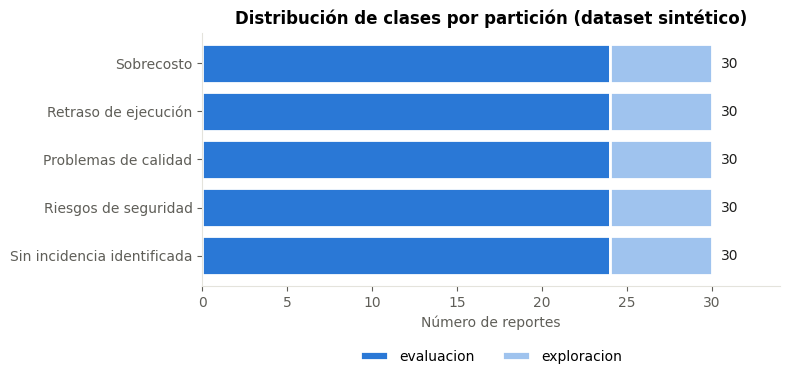

In [13]:
import matplotlib.pyplot as plt

# Paleta categórica fija (slots 1-3, validados para daltonismo) y tinta de texto neutra
COLORES = {"MiniLMv2-L6": "#2a78d6", "mDeBERTa-v3-base": "#eb6834", "XLM-RoBERTa-large": "#1baf7a"}
TINTA, TINTA_SECUNDARIA, REJILLA = "#1f1f1e", "#5f5e58", "#e4e3dc"
plt.rcParams.update({"axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_SECUNDARIA, "xtick.color": TINTA_SECUNDARIA,
                     "ytick.color": TINTA_SECUNDARIA, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

conteo = df.groupby(["categoria_real", "particion"]).size().unstack().reindex(CATEGORIAS)
fig, ax = plt.subplots(figsize=(8, 4))
izq = np.zeros(len(conteo))
for part, color in [("evaluacion", "#2a78d6"), ("exploracion", "#9fc3ee")]:
    ax.barh(conteo.index, conteo[part], left=izq, color=color, edgecolor="white", linewidth=2, label=part)
    izq += conteo[part].values
for i, total in enumerate(izq):
    ax.text(total + 0.5, i, f"{int(total)}", va="center", color=TINTA)
ax.invert_yaxis(); ax.set_xlabel("Número de reportes"); ax.set_xlim(0, 34)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_title("Distribución de clases por partición (dataset sintético)")
plt.tight_layout(); plt.savefig("results/figuras/distribucion_clases.png", dpi=150); plt.show()

## 6. Preparación de la evaluación

In [14]:
df_exp, df_eval = separar_particiones(df)
assert len(df_exp) == 30 and len(df_eval) == 120
assert set(df_exp["id_reporte"]).isdisjoint(df_eval["id_reporte"])

for nombre, v in VARIANTES_ETIQUETAS.items():
    inverso = invertir_etiquetas(v["etiquetas"])          # valida correspondencia 1 a 1
    print(f"\nVariante {nombre} — plantilla: '{v['plantilla']}'")
    for cat, etq in v["etiquetas"].items():
        print(f"  {cat:<28} → hipótesis: {v['plantilla'].format(etq)}")

print(f"\nCategorías críticas (recall mínimo {UMBRAL_RECALL_CRITICO}): {CATEGORIAS_CRITICAS}")


Variante A_nombres_cortos — plantilla: 'Este reporte de obra trata sobre {}.'
  Sobrecosto                   → hipótesis: Este reporte de obra trata sobre sobrecosto.
  Retraso de ejecución         → hipótesis: Este reporte de obra trata sobre retraso de ejecución.
  Problemas de calidad         → hipótesis: Este reporte de obra trata sobre problemas de calidad.
  Riesgos de seguridad         → hipótesis: Este reporte de obra trata sobre riesgos de seguridad.
  Sin incidencia identificada  → hipótesis: Este reporte de obra trata sobre sin incidencia.

Variante B_descriptivas — plantilla: 'En este reporte de obra se describe {}.'
  Sobrecosto                   → hipótesis: En este reporte de obra se describe un gasto mayor al presupuestado o un aumento de precios.
  Retraso de ejecución         → hipótesis: En este reporte de obra se describe un retraso o atraso en los trabajos o entregas.
  Problemas de calidad         → hipótesis: En este reporte de obra se describe un defecto o mala

## 7. Carga de modelos y ajuste mínimo (partición de exploración)

In [15]:
from src.config import MODELOS

def ejecutar_seguro(nombre, funcion):
    # Ejecuta una etapa capturando errores conocidos sin ocultarlos
    try:
        return funcion(), None
    except torch.cuda.OutOfMemoryError as e:
        msg = f"Memoria GPU insuficiente: {e}"
    except OSError as e:
        msg = f"Error de descarga o de archivos del modelo: {e}"
    except (ValueError, ImportError, AssertionError) as e:
        msg = f"Error de compatibilidad: {type(e).__name__}: {e}"
    print(f"❌ {nombre}: {msg}")
    return None, msg

errores = {}
info_carga, filas_exp, pred_exp = {}, [], []

for nombre, meta in MODELOS.items():
    cargado, err = ejecutar_seguro(nombre, lambda: cargar_modelo(nombre, meta["id"], token=HF_TOKEN))
    if err:
        errores[nombre] = err
        liberar_modelo(None)
        continue
    memoria_tras_carga = torch.cuda.memory_allocated() / 1024**2 if GPU_DISPONIBLE else None
    info_carga[nombre] = {"dispositivo": cargado.dispositivo, "dtype": cargado.dtype,
                          "parametros_contados": cargado.parametros_contados,
                          "segundos_carga_incluye_descarga": cargado.segundos_carga,
                          "memoria_gpu_tras_carga_mb": memoria_tras_carga, "revision": cargado.revision}
    if GPU_DISPONIBLE:
        assert str(cargado.clasificador.device).startswith("cuda"), f"{nombre} no quedó en GPU"
    print(f"✅ {nombre}: {cargado.parametros_contados/1e6:.1f} M parámetros | {cargado.dispositivo} | "
          f"{cargado.dtype} | carga {cargado.segundos_carga:.1f} s")

    for nombre_var, v in VARIANTES_ETIQUETAS.items():
        inverso = invertir_etiquetas(v["etiquetas"])
        r, err = ejecutar_seguro(nombre, lambda: clasificar_textos(
            cargado, df_exp["texto_reporte"].tolist(), list(v["etiquetas"].values()), v["plantilla"], N_CALENTAMIENTO))
        if err:
            errores[f"{nombre}/{nombre_var}"] = err
            continue
        p = salidas_a_dataframe(r["salidas"], df_exp, inverso, nombre, r["latencias_s"]).assign(variante=nombre_var)
        m = calcular_metricas(p["categoria_real"].tolist(), p["categoria_predicha"].tolist())
        pred_exp.append(p)
        filas_exp.append({"modelo": nombre, "variante": nombre_var, "accuracy": m["accuracy"], "f1_macro": m["f1_macro"]})
    liberar_modelo(cargado)
    del cargado

tabla_exp = pd.DataFrame(filas_exp)
tabla_exp.to_csv("results/exploracion_variantes.csv", index=False, encoding="utf-8")
display(tabla_exp.pivot(index="modelo", columns="variante", values=["accuracy", "f1_macro"]).round(3))

assert not errores, f"Hubo errores en la exploración: {errores}"
VARIANTE = tabla_exp.groupby("variante")["f1_macro"].mean().idxmax()
print(f"\nVariante elegida con la partición de exploración: {VARIANTE}")

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/565 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

...

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ XLM-RoBERTa-large: 559.9 M parámetros | cuda:0 (Tesla T4) | torch.float32 | carga 22.9 s


accuracy                        f1_macro  \
variante          A_nombres_cortos B_descriptivas A_nombres_cortos   
modelo                                                               
MiniLMv2-L6                  0.233          0.300            0.157   
XLM-RoBERTa-large            0.567          0.633            0.548   
mDeBERTa-v3-base             0.633          0.500            0.613   

                                  
variante          B_descriptivas  
modelo                            
MiniLMv2-L6                0.274  
XLM-RoBERTa-large          0.621  
mDeBERTa-v3-base           0.421


Variante elegida con la partición de exploración: A_nombres_cortos


## 8. Inferencia sobre la partición de evaluación

In [16]:
v = VARIANTES_ETIQUETAS[VARIANTE]
INVERSO = invertir_etiquetas(v["etiquetas"])
CANDIDATAS = list(v["etiquetas"].values())
PLANTILLA = v["plantilla"]

predicciones, crudos = [], {}
for nombre, meta in MODELOS.items():
    cargado, err = ejecutar_seguro(nombre, lambda: cargar_modelo(nombre, meta["id"], token=HF_TOKEN))
    if err:
        errores[nombre] = err; liberar_modelo(None); continue
    r, err = ejecutar_seguro(nombre, lambda: clasificar_textos(
        cargado, df_eval["texto_reporte"].tolist(), CANDIDATAS, PLANTILLA, N_CALENTAMIENTO))
    if err:
        errores[nombre] = err; liberar_modelo(cargado); continue
    p = salidas_a_dataframe(r["salidas"], df_eval, INVERSO, nombre, r["latencias_s"])
    p["version_modelo"] = f"{meta['id']}@{(cargado.revision or 'desconocida')[:12]}"
    p["dispositivo"] = cargado.dispositivo
    predicciones.append(p)
    crudos[nombre] = {"memoria_pico_gpu_mb": r["memoria_pico_gpu_mb"], "tiempo_total_s": r["tiempo_total_s"]}
    print(f"✅ {nombre}: {len(p)} reportes en {r['tiempo_total_s']:.2f} s ({cargado.dispositivo})")
    liberar_modelo(cargado); del cargado

assert not errores, f"Hubo errores durante la inferencia: {errores}"
df_pred = pd.concat(predicciones, ignore_index=True)
df_pred.to_csv("results/predicciones_evaluacion.csv", index=False, encoding="utf-8")
display(df_pred.groupby("modelo").head(3)[["modelo", "id_reporte", "categoria_real", "categoria_predicha",
                                           "puntuacion_modelo", "latencia_s"]])

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

✅ MiniLMv2-L6: 120 reportes en 3.56 s (cuda:0 (Tesla T4))


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

✅ mDeBERTa-v3-base: 120 reportes en 17.19 s (cuda:0 (Tesla T4))


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ XLM-RoBERTa-large: 120 reportes en 15.99 s (cuda:0 (Tesla T4))


,modelo,id_reporte,categoria_real,categoria_predicha,puntuacion_modelo,latencia_s
0,MiniLMv2-L6,VRK-CAL-002,Problemas de calidad,Sobrecosto,0.355998,0.028746
1,MiniLMv2-L6,VRK-CAL-004,Problemas de calidad,Sobrecosto,0.816218,0.028735
2,MiniLMv2-L6,VRK-CAL-006,Problemas de calidad,Sobrecosto,0.379711,0.029174
120,mDeBERTa-v3-base,VRK-CAL-002,Problemas de calidad,Retraso de ejecución,0.532425,0.119588
121,mDeBERTa-v3-base,VRK-CAL-004,Problemas de calidad,Retraso de ejecución,0.555414,0.127786
122,mDeBERTa-v3-base,VRK-CAL-006,Problemas de calidad,Retraso de ejecución,0.568451,0.125777
240,XLM-RoBERTa-large,VRK-CAL-002,Problemas de calidad,Problemas de calidad,0.480587,0.089664
241,XLM-RoBERTa-large,VRK-CAL-004,Problemas de calidad,Sobrecosto,0.434590,0.103498
242,XLM-RoBERTa-large,VRK-CAL-006,Problemas de calidad,Sobrecosto,0.884182,0.099270


## 9. Métricas de desempeño

In [17]:
metricas = {}
for nombre in MODELOS:
    p = df_pred[df_pred["modelo"] == nombre]
    m = calcular_metricas(p["categoria_real"].tolist(), p["categoria_predicha"].tolist())
    m.update(resumen_latencia(p["latencia_s"].tolist()))
    m["memoria_pico_gpu_mb"] = crudos[nombre]["memoria_pico_gpu_mb"]
    m["puntuacion_media"] = float(p["puntuacion_modelo"].mean())
    m["puntuacion_media_aciertos"] = float(p.loc[p["acierto"], "puntuacion_modelo"].mean())
    m["puntuacion_media_errores"] = float(p.loc[~p["acierto"], "puntuacion_modelo"].mean()) if (~p["acierto"]).any() else float("nan")
    metricas[nombre] = m
    print(f"\n=== {nombre} ===  accuracy={m['accuracy']:.3f} | F1 macro={m['f1_macro']:.3f} | "
          f"latencia media={m['latencia_media_ms']:.1f} ms")
    display(m["por_categoria"].round(3))

por_categoria = pd.concat({n: m["por_categoria"] for n, m in metricas.items()}, names=["modelo", "categoria"])
por_categoria.to_csv("results/metricas_por_categoria.csv", encoding="utf-8")


=== MiniLMv2-L6 ===  accuracy=0.225 | F1 macro=0.197 | latencia media=29.6 ms


,precision,recall,f1,soporte
Sobrecosto,0.115,0.125,0.120,24
Retraso de ejecución,0.296,0.667,0.410,24
Problemas de calidad,0.050,0.042,0.045,24
Riesgos de seguridad,0.300,0.125,0.176,24
Sin incidencia identificada,0.400,0.167,0.235,24



=== mDeBERTa-v3-base ===  accuracy=0.517 | F1 macro=0.498 | latencia media=143.2 ms


,precision,recall,f1,soporte
Sobrecosto,0.938,0.625,0.750,24
Retraso de ejecución,0.354,0.958,0.517,24
Problemas de calidad,0.364,0.167,0.229,24
Riesgos de seguridad,0.625,0.208,0.312,24
Sin incidencia identificada,0.750,0.625,0.682,24



=== XLM-RoBERTa-large ===  accuracy=0.575 | F1 macro=0.543 | latencia media=133.2 ms


,precision,recall,f1,soporte
Sobrecosto,0.478,0.917,0.629,24
Retraso de ejecución,0.543,0.792,0.644,24
Problemas de calidad,0.786,0.458,0.579,24
Riesgos de seguridad,1.000,0.167,0.286,24
Sin incidencia identificada,0.619,0.542,0.578,24


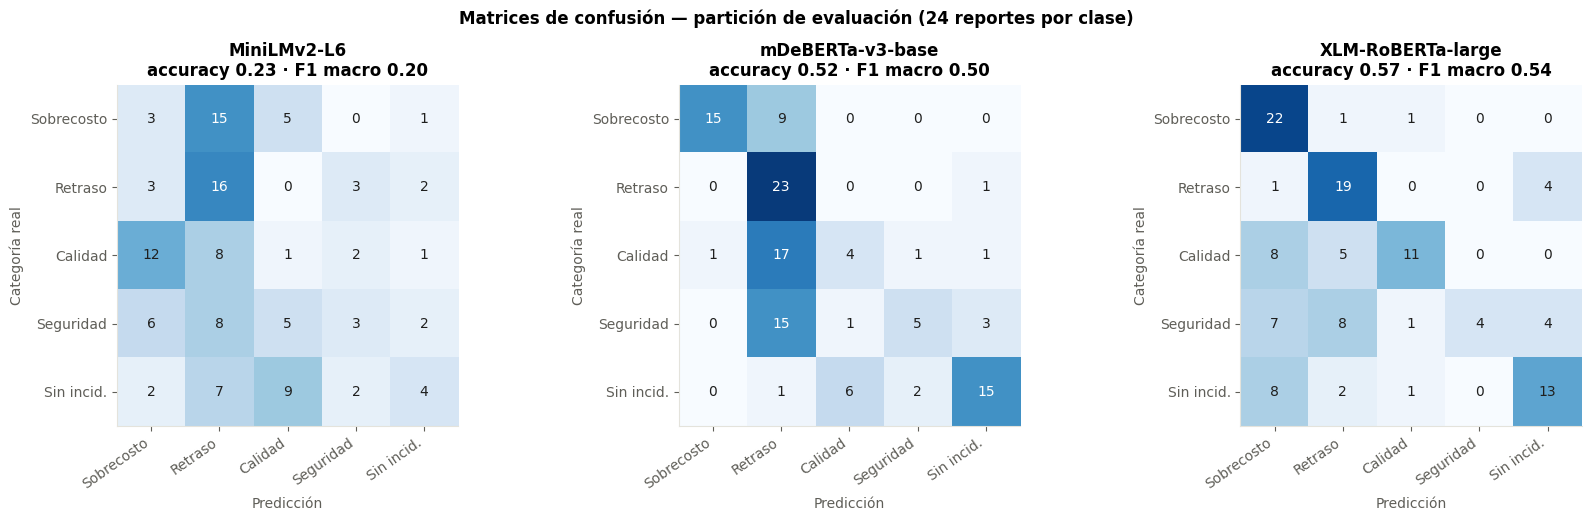

In [18]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 5.2))
etiquetas_cortas = ["Sobrecosto", "Retraso", "Calidad", "Seguridad", "Sin incid."]
for ax, (nombre, m) in zip(ejes, metricas.items()):
    mat = m["matriz_confusion"].values
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=24)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=10,
                    color="white" if mat[i, j] > 14 else TINTA)
    ax.set_xticks(range(5), etiquetas_cortas, rotation=35, ha="right")
    ax.set_yticks(range(5), etiquetas_cortas)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Categoría real")
    ax.set_title(f"{nombre}\naccuracy {m['accuracy']:.2f} · F1 macro {m['f1_macro']:.2f}")
plt.suptitle("Matrices de confusión — partición de evaluación (24 reportes por clase)", fontweight="bold")
plt.tight_layout(); plt.savefig("results/figuras/matrices_confusion.png", dpi=150); plt.show()

## 10. Comparación consolidada

In [19]:
filas = []
for nombre, m in metricas.items():
    filas.append({
        "modelo": nombre,
        "parametros_M": round(info_carga[nombre]["parametros_contados"] / 1e6, 1),
        "licencia": info_hub[nombre]["licencia"],
        "dispositivo": info_carga[nombre]["dispositivo"],
        "accuracy": m["accuracy"], "precision_macro": m["precision_macro"],
        "recall_macro": m["recall_macro"], "f1_macro": m["f1_macro"],
        "latencia_media_ms": m["latencia_media_ms"], "latencia_p95_ms": m["latencia_p95_ms"],
        "tiempo_total_s": m["tiempo_total_s"], "reportes_por_segundo": m["reportes_por_segundo"],
        "memoria_pico_gpu_mb": m["memoria_pico_gpu_mb"],
        "puntuacion_media": m["puntuacion_media"],
        **{f"recall_{c}": m["por_categoria"].loc[c, "recall"] for c in CATEGORIAS},
    })
tabla = pd.DataFrame(filas).set_index("modelo")
tabla.to_csv("results/metricas_comparativas.csv", encoding="utf-8")
display(tabla.round(3).T)

modelo,MiniLMv2-L6,mDeBERTa-v3-base,XLM-RoBERTa-large
parametros_M,107.0,278.8,559.9
licencia,mit,mit,mit
dispositivo,cuda:0 (Tesla T4),cuda:0 (Tesla T4),cuda:0 (Tesla T4)
accuracy,0.225,0.517,0.575
precision_macro,0.232,0.606,0.685
recall_macro,0.225,0.517,0.575
f1_macro,0.197,0.498,0.543
latencia_media_ms,29.647,143.214,133.213
latencia_p95_ms,38.853,198.577,359.193
tiempo_total_s,3.558,17.186,15.986


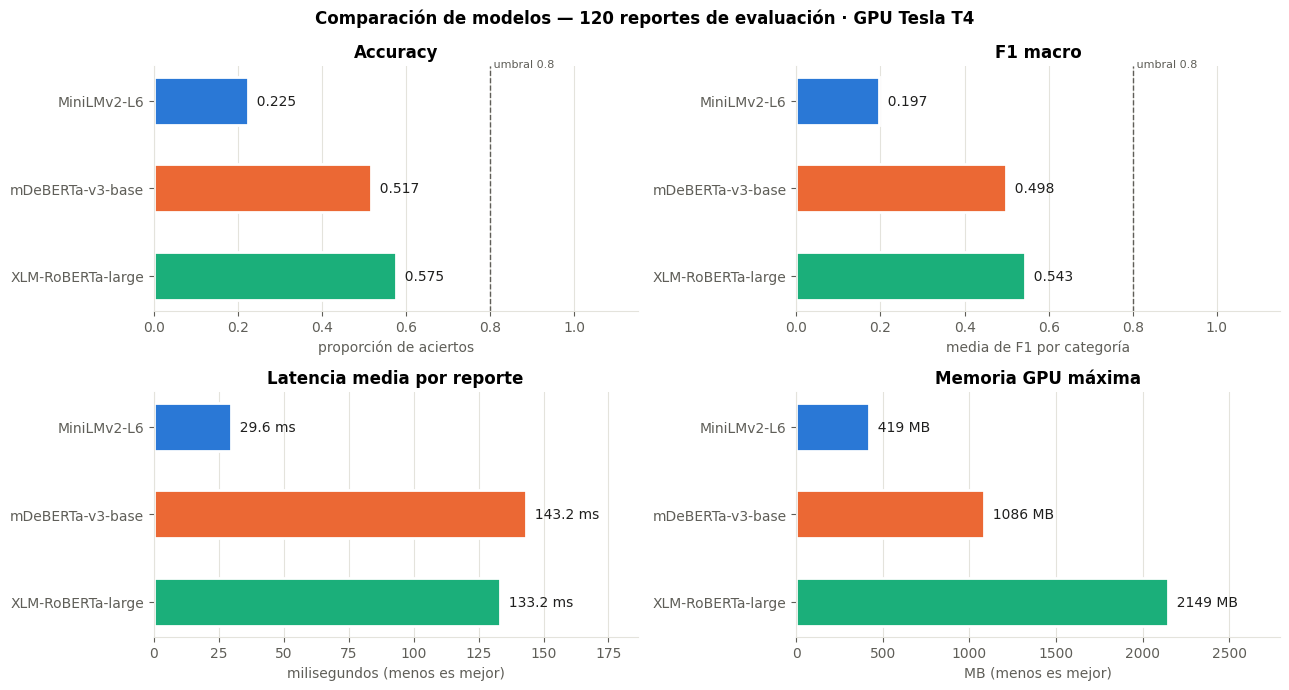

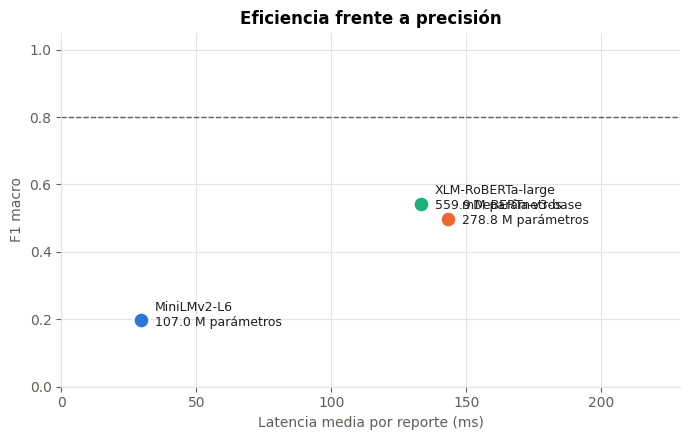

In [20]:
modelos = list(tabla.index)
colores = [COLORES[m] for m in modelos]

def barras(ax, valores, titulo, formato, xlabel, limite=None, referencia=None):
    y = np.arange(len(modelos))
    ax.barh(y, valores, color=colores, height=0.55, edgecolor="white", linewidth=2)
    for i, val in enumerate(valores):
        ax.text(val, i, f"  {formato.format(val)}", va="center", color=TINTA)
    ax.set_yticks(y, modelos); ax.invert_yaxis(); ax.set_title(titulo); ax.set_xlabel(xlabel)
    ax.grid(axis="x", color=REJILLA, linewidth=0.8); ax.set_axisbelow(True)
    if limite: ax.set_xlim(0, limite)
    if referencia is not None:
        ax.axvline(referencia, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
        ax.text(referencia, -0.42, f" umbral {referencia}", va="center", color=TINTA_SECUNDARIA, fontsize=8)

fig, ejes = plt.subplots(2, 2, figsize=(13, 7))
barras(ejes[0, 0], tabla["accuracy"], "Accuracy", "{:.3f}", "proporción de aciertos", 1.15, UMBRAL_ACCURACY)
barras(ejes[0, 1], tabla["f1_macro"], "F1 macro", "{:.3f}", "media de F1 por categoría", 1.15, UMBRAL_F1_MACRO)
barras(ejes[1, 0], tabla["latencia_media_ms"], "Latencia media por reporte", "{:.1f} ms", "milisegundos (menos es mejor)",
       tabla["latencia_media_ms"].max() * 1.3)
if tabla["memoria_pico_gpu_mb"].notna().all():
    barras(ejes[1, 1], tabla["memoria_pico_gpu_mb"], "Memoria GPU máxima", "{:.0f} MB", "MB (menos es mejor)",
           tabla["memoria_pico_gpu_mb"].max() * 1.3)
else:
    barras(ejes[1, 1], tabla["parametros_M"], "Parámetros (sin GPU para medir memoria)", "{:,.1f} M", "millones",
           tabla["parametros_M"].max() * 1.3)
dispositivo = "GPU " + str(entorno["gpu"]) if GPU_DISPONIBLE else "CPU (sin GPU)"
plt.suptitle(f"Comparación de modelos — 120 reportes de evaluación · {dispositivo}", fontweight="bold")
plt.tight_layout(); plt.savefig("results/figuras/comparacion_modelos.png", dpi=150); plt.show()

# Relación eficiencia-precisión
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in modelos:
    ax.scatter(tabla.loc[m, "latencia_media_ms"], tabla.loc[m, "f1_macro"], s=140, color=COLORES[m],
               edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"{m}\n{tabla.loc[m, 'parametros_M']:,.1f} M parámetros",
                (tabla.loc[m, "latencia_media_ms"], tabla.loc[m, "f1_macro"]),
                textcoords="offset points", xytext=(10, -4), fontsize=9, color=TINTA)
ax.axhline(UMBRAL_F1_MACRO, color=TINTA_SECUNDARIA, linestyle="--", linewidth=1)
ax.set_xlabel("Latencia media por reporte (ms)"); ax.set_ylabel("F1 macro")
ax.set_xlim(0, tabla["latencia_media_ms"].max() * 1.6); ax.set_ylim(0, 1.05)
ax.grid(color=REJILLA, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("Eficiencia frente a precisión")
plt.tight_layout(); plt.savefig("results/figuras/eficiencia_vs_precision.png", dpi=150); plt.show()

In [21]:
# Errores de clasificación más frecuentes
errs = errores_frecuentes(df_pred, top=5)
errs.to_csv("results/errores_frecuentes.csv", index=False, encoding="utf-8")
display(errs)

# Exactitud por tipo de redacción y en reportes con múltiples incidencias
por_tipo = df_pred.pivot_table(index="tipo_redaccion", columns="modelo", values="acierto", aggfunc="mean")
por_tipo["n_reportes"] = df_pred[df_pred["modelo"] == modelos[0]].groupby("tipo_redaccion").size()
display(por_tipo.round(3))
multi = df_pred.pivot_table(index="multiples_incidencias", columns="modelo", values="acierto", aggfunc="mean")
display(multi.round(3))

# Ejemplos de errores del modelo con mejor F1
mejor_f1 = tabla["f1_macro"].idxmax()
display(df_pred[(df_pred["modelo"] == mejor_f1) & (~df_pred["acierto"])]
        [["id_reporte", "texto_reporte", "categoria_real", "categoria_predicha", "puntuacion_modelo"]].head(10))

# Conclusión parcial generada a partir de los datos (no escrita a mano)
for m in modelos:
    e = errs[errs["modelo"] == m]
    if len(e):
        top = e.iloc[0]
        print(f"• {m}: el error más frecuente es '{top['categoria_real']}' → '{top['categoria_predicha']}' "
              f"({top['casos']} casos).")
peor_tipo = por_tipo[modelos].mean(axis=1).idxmin()
print(f"• El tipo de redacción más difícil en promedio fue '{peor_tipo}' "
      f"(exactitud media {por_tipo.loc[peor_tipo, modelos].mean():.2f}).")

,modelo,categoria_real,categoria_predicha,casos
0,MiniLMv2-L6,Sobrecosto,Retraso de ejecución,15
1,MiniLMv2-L6,Problemas de calidad,Sobrecosto,12
2,MiniLMv2-L6,Sin incidencia identificada,Problemas de calidad,9
3,MiniLMv2-L6,Problemas de calidad,Retraso de ejecución,8
4,MiniLMv2-L6,Riesgos de seguridad,Retraso de ejecución,8
5,XLM-RoBERTa-large,Problemas de calidad,Sobrecosto,8
6,XLM-RoBERTa-large,Riesgos de seguridad,Retraso de ejecución,8
7,XLM-RoBERTa-large,Sin incidencia identificada,Sobrecosto,8
8,XLM-RoBERTa-large,Riesgos de seguridad,Sobrecosto,7
9,XLM-RoBERTa-large,Problemas de calidad,Retraso de ejecución,5


modelo,MiniLMv2-L6,XLM-RoBERTa-large,mDeBERTa-v3-base,n_reportes
tipo_redaccion,,,,
ambiguo,0.182,0.545,0.364,11
coloquial,0.308,0.846,0.538,13
contraste,0.000,0.500,0.333,6
directo,0.203,0.500,0.500,64
negacion,0.308,0.654,0.654,26


modelo,MiniLMv2-L6,XLM-RoBERTa-large,mDeBERTa-v3-base
multiples_incidencias,,,
False,0.227,0.582,0.536
True,0.200,0.500,0.300


,id_reporte,texto_reporte,categoria_real,categoria_predicha,puntuacion_modelo
241,VRK-CAL-004,Al descimbrar la columna C-3 aparecieron oqued...,Problemas de calidad,Sobrecosto,0.434590
242,VRK-CAL-006,En la prueba de la red hidráulica bajó la pres...,Problemas de calidad,Sobrecosto,0.884182
243,VRK-CAL-007,Las juntas del azulejo de la cocina quedaron d...,Problemas de calidad,Retraso de ejecución,0.370036
244,VRK-CAL-008,La pintura de la fachada ya se está descarapel...,Problemas de calidad,Retraso de ejecución,0.523459
246,VRK-CAL-010,Los contactos de la sala no tienen tierra físi...,Problemas de calidad,Retraso de ejecución,0.437787
247,VRK-CAL-011,El piso terminado quedó dos centímetros más al...,Problemas de calidad,Sobrecosto,0.866523
248,VRK-CAL-012,La pendiente de la azotea no lleva el agua a l...,Problemas de calidad,Sobrecosto,0.450248
251,VRK-CAL-017,Los muros de block no están a plomo; en la esq...,Problemas de calidad,Sobrecosto,0.450076
253,VRK-CAL-019,En el plafón de tablaroca se marcan todas las ...,Problemas de calidad,Sobrecosto,0.450452
255,VRK-CAL-021,Colocaron el piso sin respetar el despiece apr...,Problemas de calidad,Sobrecosto,0.660635


• MiniLMv2-L6: el error más frecuente es 'Sobrecosto' → 'Retraso de ejecución' (15 casos).
• mDeBERTa-v3-base: el error más frecuente es 'Problemas de calidad' → 'Retraso de ejecución' (17 casos).
• XLM-RoBERTa-large: el error más frecuente es 'Problemas de calidad' → 'Sobrecosto' (8 casos).
• El tipo de redacción más difícil en promedio fue 'contraste' (exactitud media 0.28).


## 11. Evaluación de umbrales y revisión humana

In [22]:
filas_u = []
for nombre, m in metricas.items():
    u = evaluar_umbrales(m)
    p = df_pred[df_pred["modelo"] == nombre]
    criticos_no_detectados = p[(p["categoria_real"].isin(CATEGORIAS_CRITICAS)) & (~p["acierto"]) & (~p["requiere_revision_humana"])]
    filas_u.append({
        "modelo": nombre,
        "accuracy": round(m["accuracy"], 3), "cumple_accuracy": u["cumple_accuracy"],
        "f1_macro": round(m["f1_macro"], 3), "cumple_f1_macro": u["cumple_f1_macro"],
        "recall_critico_min": round(u["recall_critico_minimo"], 3), "categoria_mas_debil": u["categoria_recall_minimo"],
        "cumple_recall_critico": u["cumple_recall_critico"], "cumple_todos": u["cumple_todos"],
        "pct_revision_humana": round(p["requiere_revision_humana"].mean() * 100, 1),
        "errores_criticos_sin_revision": len(criticos_no_detectados),
    })
tabla_umbrales = pd.DataFrame(filas_u).set_index("modelo")
tabla_umbrales.to_csv("results/evaluacion_umbrales.csv", encoding="utf-8")
display(tabla_umbrales)

,accuracy,cumple_accuracy,f1_macro,cumple_f1_macro,recall_critico_min,categoria_mas_debil,cumple_recall_critico,cumple_todos,pct_revision_humana,errores_criticos_sin_revision
modelo,,,,,,,,,,
MiniLMv2-L6,0.225,False,0.197,False,0.042,Problemas de calidad,False,False,69.2,14
mDeBERTa-v3-base,0.517,False,0.498,False,0.167,Problemas de calidad,False,False,25.8,38
XLM-RoBERTa-large,0.575,False,0.543,False,0.167,Riesgos de seguridad,False,False,37.5,21


## 12. Recomendación del modelo

In [23]:
cumplen = tabla_umbrales[tabla_umbrales["cumple_todos"]].index.tolist()
if cumplen:
    RECOMENDADO = tabla.loc[cumplen, "latencia_media_ms"].idxmin()
    motivo = "cumple los tres umbrales y es el más rápido entre los que los cumplen"
else:
    RECOMENDADO = tabla["f1_macro"].idxmax()
    motivo = ("ningún modelo cumple los tres umbrales; se elige el de mayor F1 macro como candidato, "
              "condicionado a revisión humana y a un ajuste fino posterior")

t = tabla.loc[RECOMENDADO]
print(f"Modelo recomendado: {RECOMENDADO} ({MODELOS[RECOMENDADO]['id']})")
print(f"Motivo: {motivo}.")
print(f"Accuracy {t['accuracy']:.3f} · F1 macro {t['f1_macro']:.3f} · latencia media {t['latencia_media_ms']:.1f} ms · "
      f"{t['parametros_M']:.0f} M parámetros · licencia {t['licencia']} · {t['dispositivo']}")
for otro in [m for m in modelos if m != RECOMENDADO]:
    d_f1 = t["f1_macro"] - tabla.loc[otro, "f1_macro"]
    r_lat = tabla.loc[otro, "latencia_media_ms"] / t["latencia_media_ms"]
    print(f"  vs {otro}: diferencia F1 macro {d_f1:+.3f}; {otro} tarda {r_lat:.2f} veces lo del recomendado")

recomendacion = {"modelo": RECOMENDADO, "id": MODELOS[RECOMENDADO]["id"], "motivo": motivo,
                 "variante_etiquetas": VARIANTE, "modelos_que_cumplen": cumplen}
with open("results/recomendacion.json", "w", encoding="utf-8") as f:
    json.dump(recomendacion, f, ensure_ascii=False, indent=2)

Modelo recomendado: XLM-RoBERTa-large (joeddav/xlm-roberta-large-xnli)
Motivo: ningún modelo cumple los tres umbrales; se elige el de mayor F1 macro como candidato, condicionado a revisión humana y a un ajuste fino posterior.
Accuracy 0.575 · F1 macro 0.543 · latencia media 133.2 ms · 560 M parámetros · licencia mit · cuda:0 (Tesla T4)
  vs MiniLMv2-L6: diferencia F1 macro +0.346; MiniLMv2-L6 tarda 0.22 veces lo del recomendado
  vs mDeBERTa-v3-base: diferencia F1 macro +0.045; mDeBERTa-v3-base tarda 1.08 veces lo del recomendado


## 13. Prueba funcional VOREKO

In [24]:
COMENTARIOS_NUEVOS = [
    "El de la pipa no llegó y nos quedamos sin agua para el colado de mañana.",
    "Me facturaron el cemento gris a precio de cemento blanco, revisen la nota.",
    "La escalera quedó con huellas de distinto tamaño, el último escalón está más alto.",
    "El chalán anda trepado en la barda sin nada que lo sostenga.",
    "Se terminaron de colocar las luminarias y todas encienden.",
    "La loseta llegó tarde y además más cara de lo cotizado.",
]
assert not set(COMENTARIOS_NUEVOS) & set(df["texto_reporte"]), "Los comentarios de prueba deben ser nuevos"

cargado = cargar_modelo(RECOMENDADO, MODELOS[RECOMENDADO]["id"], token=HF_TOKEN)
version_modelo = f"{MODELOS[RECOMENDADO]['id']}@{(cargado.revision or 'desconocida')[:12]}"
salidas_voreko = []
with torch.inference_mode():
    for texto in COMENTARIOS_NUEVOS:
        s = cargado.clasificador(texto, candidate_labels=CANDIDATAS, hypothesis_template=PLANTILLA, multi_label=False)
        salidas_voreko.append(salida_voreko(texto, s, INVERSO, version_modelo))
liberar_modelo(cargado); del cargado

display(pd.DataFrame(salidas_voreko)[["texto_reporte", "categoria_predicha", "puntuacion_modelo",
                                      "requiere_revision_humana", "motivo_revision"]])
json_voreko = a_json(salidas_voreko)
Path("results/ejemplo_respuesta_voreko.json").write_text(json_voreko, encoding="utf-8")
print(json_voreko[:900])

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: joeddav/xlm-roberta-large-xnli
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,texto_reporte,categoria_predicha,puntuacion_modelo,requiere_revision_humana,motivo_revision
0,El de la pipa no llegó y nos quedamos sin agua...,Retraso de ejecución,0.7707,False,None
1,Me facturaron el cemento gris a precio de ceme...,Sobrecosto,0.9715,False,None
2,La escalera quedó con huellas de distinto tama...,Sobrecosto,0.2941,True,puntuacion_baja;prediccion_ambigua
3,El chalán anda trepado en la barda sin nada qu...,Sin incidencia identificada,0.6120,False,None
4,Se terminaron de colocar las luminarias y toda...,Sobrecosto,0.3325,True,puntuacion_baja;prediccion_ambigua
5,La loseta llegó tarde y además más cara de lo ...,Retraso de ejecución,0.4965,True,puntuacion_baja;prediccion_ambigua


[
  {
    "texto_reporte": "El de la pipa no llegó y nos quedamos sin agua para el colado de mañana.",
    "categoria_predicha": "Retraso de ejecución",
    "puntuacion_modelo": 0.7707,
    "requiere_revision_humana": false,
    "motivo_revision": null,
    "version_modelo": "joeddav/xlm-roberta-large-xnli@desconocida",
    "fecha_clasificacion_utc": "2026-10-12T16:30:51+00:00"
  },
  {
    "texto_reporte": "Me facturaron el cemento gris a precio de cemento blanco, revisen la nota.",
    "categoria_predicha": "Sobrecosto",
    "puntuacion_modelo": 0.9715,
    "requiere_revision_humana": false,
    "motivo_revision": null,
    "version_modelo": "joeddav/xlm-roberta-large-xnli@desconocida",
    "fecha_clasificacion_utc": "2026-10-12T16:30:51+00:00"
  },
  {
    "texto_reporte": "La escalera quedó con huellas de distinto tamaño, el último escalón está más alto.",
    "categoria_predicha": "


## 14. Revisión técnica automatizada

In [25]:
resultados_pruebas = []
def prueba(descripcion, condicion):
    resultados_pruebas.append({"prueba": descripcion, "resultado": "OK" if condicion else "FALLA"})
    assert condicion, f"FALLA: {descripcion}"

prueba("1. Dataset leído con 150 registros y 5 clases", len(df) == 150 and set(df["categoria_real"]) == set(CATEGORIAS))
prueba("2. Sin valores faltantes ni textos vacíos", df.isna().sum().sum() == 0 and df["texto_reporte"].str.strip().str.len().gt(0).all())
prueba("3. Los tres modelos terminaron sin errores", not errores and set(df_pred["modelo"]) == set(MODELOS))
prueba("4. 120 predicciones por modelo", (df_pred.groupby("modelo").size() == 120).all())
prueba("5. Mismos reportes y orden en los tres modelos",
       all((df_pred[df_pred.modelo == m]["id_reporte"].values == df_eval["id_reporte"].values).all() for m in MODELOS))
prueba("6. Predicciones dentro del catálogo de categorías", set(df_pred["categoria_predicha"]) <= set(CATEGORIAS))
prueba("7. Puntuaciones en [0, 1] y sin NaN", df_pred["puntuacion_modelo"].between(0, 1).all())
prueba("8. Accuracy recalculada a mano coincide con sklearn",
       all(abs(df_pred[df_pred.modelo == m]["acierto"].mean() - metricas[m]["accuracy"]) < 1e-9 for m in MODELOS))
prueba("9. Matrices de confusión suman 120", all(m["matriz_confusion"].values.sum() == 120 for m in metricas.values()))
prueba("10. Métricas sin NaN", not tabla[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].isna().any().any())
prueba("11. Latencias positivas y tiempo total consistente",
       (df_pred["latencia_s"] > 0).all() and all(abs(df_pred[df_pred.modelo == m]["latencia_s"].sum() - tabla.loc[m, "tiempo_total_s"]) < 1e-6 for m in MODELOS))
prueba("12. Uso de GPU cuando está disponible",
       (not GPU_DISPONIBLE) or df_pred["dispositivo"].str.startswith("cuda").all())
prueba("13. Memoria GPU medida cuando hay GPU", (not GPU_DISPONIBLE) or tabla["memoria_pico_gpu_mb"].gt(0).all())
prueba("14. Tabla consolidada coherente con las predicciones", set(tabla.index) == set(MODELOS))
prueba("15. Variante elegida sólo con exploración", VARIANTE in VARIANTES_ETIQUETAS and len(tabla_exp) == 2 * len(MODELOS))
prueba("16. Salida VOREKO con los campos requeridos",
       all({"texto_reporte", "categoria_predicha", "puntuacion_modelo", "requiere_revision_humana", "version_modelo"} <= set(s) for s in salidas_voreko))
archivos = ["entorno_ejecucion.json", "modelos_hub.json", "exploracion_variantes.csv", "predicciones_evaluacion.csv",
            "metricas_por_categoria.csv", "metricas_comparativas.csv", "errores_frecuentes.csv", "evaluacion_umbrales.csv",
            "recomendacion.json", "ejemplo_respuesta_voreko.json", "figuras/comparacion_modelos.png",
            "figuras/matrices_confusion.png", "figuras/eficiencia_vs_precision.png"]
entorno.update({"variante_etiquetas": VARIANTE, "info_carga": info_carga})
with open("results/entorno_ejecucion.json", "w", encoding="utf-8") as f:
    json.dump(entorno, f, ensure_ascii=False, indent=2, default=str)
prueba("17. Resultados exportados en results/", all(Path("results", a).exists() for a in archivos))
prueba("18. Ningún token en los archivos exportados",
       not HF_TOKEN or all(HF_TOKEN not in Path(r).read_text(encoding="utf-8", errors="ignore")
                           for r in Path("results").rglob("*") if r.suffix in {".json", ".csv"}))

df_pruebas = pd.DataFrame(resultados_pruebas)
df_pruebas.to_csv("results/revision_tecnica.csv", index=False, encoding="utf-8")
display(df_pruebas)
print(f"\n✅ {len(df_pruebas)} de {len(df_pruebas)} comprobaciones superadas en {'GPU ' + str(entorno['gpu']) if GPU_DISPONIBLE else 'CPU'}.")

,prueba,resultado
0,1. Dataset leído con 150 registros y 5 clases,OK
1,2. Sin valores faltantes ni textos vacíos,OK
2,3. Los tres modelos terminaron sin errores,OK
3,4. 120 predicciones por modelo,OK
4,5. Mismos reportes y orden en los tres modelos,OK
5,6. Predicciones dentro del catálogo de categorías,OK
6,"7. Puntuaciones en [0, 1] y sin NaN",OK
7,8. Accuracy recalculada a mano coincide con sk...,OK
8,9. Matrices de confusión suman 120,OK
9,10. Métricas sin NaN,OK



✅ 18 de 18 comprobaciones superadas en GPU Tesla T4.


## 15. Exportación de resultados

In [26]:
shutil.make_archive("resultados_voreko_ia", "zip", "results")
print("Archivo generado: resultados_voreko_ia.zip")
try:
    from google.colab import files
    files.download("resultados_voreko_ia.zip")
except ImportError:
    print("Fuera de Colab: el ZIP queda en la carpeta de trabajo.")

Archivo generado: resultados_voreko_ia.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>